# Финальный экзамен: анализ данных плей-офф НХЛ 2025/2026

**Курс:** Анализ данных в Python (РЭШ, программы ФИБ / ИИФТ)

---

## Содержание

| № | Задание | № | Задание |
|---|---------|---|---------|
| 1 | Загрузка данных | 12 | Средние броски и голы по командам |
| 2 | Сводная таблица по играм | 13 | Регрессионная диаграмма |
| 3 | Функция `gameInfo()` | 14 | Матч с максимумом ударов |
| 4 | Суммарный счёт и его статистики | 15 | Карта бросков на площадке |
| 5 | Гистограмма числа голов | 16 | Топ‑10 снайперов |
| 6 | Самые «сухие» и самые результативные матчи | 17 | Топ‑10 по передачам |
| 7 | Число игроков в матче | 18 | Топ‑10 по системе «гол+пас» |
| 8 | Расстояние до ворот | 19 | Топ‑10 по броскам за игру |
| 9 | Распределение длины точных/неточных бросков | 20 | Топ‑10 по силовым приёмам |
| 10 | Доля точных бросков | 21 | Вратари с «сухими» матчами |
| 11 | Лучшие и худшие команды по точности | 22 | Собственное исследование |

---

## Краткая сводка результатов

* В выборке **29 710 событий** из **82 матчей** плей‑офф, 16 команд, 372 игрока.
* Забито **486 голов** — в среднем **5.93** за матч (σ = 2.26); разброс от 1 до 15.
* Самый результативный матч — *Colorado Avalanche – Minnesota Wild (9 – 6)*; два матча
  закончились со счётом 1 – 0 в овертайме.
* Самая «настрелянная» игра — *Carolina Hurricanes – Ottawa Senators (3 – 2, Final/2OT)*:
  **208** ударов по воротам.
* Доля точных бросков у команд колеблется в узком коридоре **0.55 – 0.71**, то есть это
  скорее свойство лиги, чем отличительная черта команды.
* Связь «броски → голы» положительная и значимая на 5 % (*r* = 0.52, *p* = 0.04), но
  объясняет лишь **27 %** различий в результативности.
* Лучший бомбардир — **Mitch Marner** (29 очков), лучший снайпер — **Brett Howden** (14 голов),
  лучший ассистент — **Jack Eichel** (20 передач).
* Главный вывод собственного исследования (п. 22): **вероятность гола падает с расстоянием
  примерно в 9 раз** — с ≈15 % с пятачка до ≈1.6 % с 60–80 футов. Но на уровне команд за один
  плей‑офф с голами связан именно *объём* бросков, а не средняя дистанция: по ней команды
  практически не различаются.

---

### Замечания о методике

Три места в условии требуют аккуратности, и в соответствующих пунктах это разобрано подробно:

1. **п. 7** — в примере условия указано 41 игрок, у нас получается **40**. Разница в том, что
   в каждом матче среди полей «игроки на льду» есть ровно одна пустая ячейка (`NaN`),
   и наивный подсчёт уникальных значений считает её за отдельного «игрока». Упорядочение матчей
   при этом не меняется.
2. **п. 15** — условие предлагает отражать координаты «в нечётных периодах». Это верно для
   разбираемого матча, но не для всех: в 31 матче из 82 хозяева в первом периоде защищают
   *левые* ворота. Мы используем общее правило по полю `Home Team's Defending Side`.
3. **п. 21** — у всех 22 овертаймных голов в данных отсутствует информация о том, кто был
   на льду, поэтому «сухие» матчи считаются двумя способами: формально и с поправкой на этот
   пропуск.

---

## 0. Подготовка рабочего окружения

Понадобятся только `numpy`, `pandas`, `matplotlib`, `seaborn` и `openpyxl` (последний — чтобы
`pandas` смог прочитать `.xlsx`). Файл `rink.py` с рисунком хоккейной площадки взят из
материалов к экзамену и лежит в той же директории.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

%matplotlib inline

# ── отображение таблиц и графиков ───────────────────────────────────────
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda v: f'{v:.3f}')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'font.size': 10,
    'axes.titlesize': 11,
})

FIGDIR = Path('figures')
FIGDIR.mkdir(exist_ok=True)

print('pandas', pd.__version__, '| numpy', np.__version__, '| seaborn', sns.__version__)

pandas 2.2.3 | numpy 1.26.4 | seaborn 0.13.2


In [2]:
def find_data(name='NHL-playoffs-2026.xlsx'):
    """Ищет файл с данными рядом с ноутбуком или на уровень выше."""
    for candidate in (Path(name), Path('..') / name):
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        f'Не найден {name}. Положите его рядом с ноутбуком.')


DATA = find_data()
print('Данные:', DATA.resolve())

Данные: C:\Users\Georg\Documents\РЭШ\Python\Final-Exam-Solution\NHL-playoffs-2026.xlsx


---

## 1. Загрузка данных

Первый столбец файла — сохранённый при экспорте индекс строк, поэтому читаем с
`index_col=0`. Без этого в наборе оказалось бы 39 столбцов вместо 38.

In [3]:
events = pd.read_excel(DATA, index_col=0)
events.shape

(29710, 38)

In [4]:
events.iloc[:10, [2, 3, 4, 9, 12]]

,Date,Away Team,Home Team,Remaining Time,Play Type
0,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,period-start
1,2026-04-19,Boston Bruins,Buffalo Sabres,20:00,faceoff
2,2026-04-19,Boston Bruins,Buffalo Sabres,19:47,hit
3,2026-04-19,Boston Bruins,Buffalo Sabres,19:46,hit
4,2026-04-19,Boston Bruins,Buffalo Sabres,19:41,hit
5,2026-04-19,Boston Bruins,Buffalo Sabres,19:27,hit
6,2026-04-19,Boston Bruins,Buffalo Sabres,19:03,hit
7,2026-04-19,Boston Bruins,Buffalo Sabres,18:53,missed-shot
8,2026-04-19,Boston Bruins,Buffalo Sabres,18:48,hit
9,2026-04-19,Boston Bruins,Buffalo Sabres,18:37,missed-shot


Форма набора — `(29710, 38)`, и первые десять строк совпадают с примером из условия.
Посмотрим на состав полей: типы, число уникальных значений и количество пропусков.

In [5]:
overview = pd.DataFrame({
    'dtype': events.dtypes.astype(str),
    'nunique': events.nunique(),
    'nulls': events.isna().sum(),
})
overview['nulls, %'] = (100 * overview['nulls'] / len(events)).round(1)
overview

,dtype,nunique,nulls,"nulls, %"
Dataset,object,1,0,0.000
Game ID,int64,82,0,0.000
Date,object,44,0,0.000
Away Team,object,16,0,0.000
Home Team,object,16,0,0.000
Cumulated Away Score,int64,9,0,0.000
Cumulated Home Score,int64,10,0,0.000
Period,int64,5,0,0.000
Elapsed Time,object,1200,0,0.000
Remaining Time,object,1200,0,0.000


Пропуски не случайны, а содержательны: у служебных событий (`period-start`, `stoppage`,
`game-end`) нет ни координат, ни игроков, ни зоны — отсюда ровно 4 843 пропуска в координатах
и 4 584 в поле `Team Making the Play`. Это нормально и ничего «чинить» не нужно.

Сразу зафиксируем словари типов событий — они понадобятся почти в каждом пункте.

In [6]:
ACCURATE = ['shot-on-goal', 'goal']                    # точные броски (дошли до ворот)
SHOTS    = ACCURATE + ['missed-shot']                  # все незаблокированные броски
ATTEMPTS = SHOTS + ['blocked-shot']                    # вообще все удары по воротам

ON_ICE_AWAY = [f"Away Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Away Team's Goalie"]
ON_ICE_HOME = [f"Home Team's Player on the Ice #{i}" for i in range(1, 7)] + ["Home Team's Goalie"]
ON_ICE = ON_ICE_AWAY + ON_ICE_HOME

events['Play Type'].value_counts().to_frame('count')

,count
Play Type,
hit,5621
faceoff,4995
shot-on-goal,4137
stoppage,3958
blocked-shot,2798
missed-shot,2643
giveaway,2604
penalty,804
takeaway,779


---

## 2. Сводная таблица по матчам

Счёт в данных накопительный (`Cumulated Away/Home Score`), поэтому итоговый счёт матча — это
значение в **последней** строке каждой игры. Число овертаймов определяется максимальным
номером периода: периоды 1–3 — основное время, период 4 — первый овертайм, 5 — второй и т. д.

In [7]:
final_rows = events.groupby('Game ID').tail(1).set_index('Game ID')


def outcome(max_period):
    """'Final' / 'Final/OT' / 'Final/2OT' ... по максимальному номеру периода."""
    if max_period <= 3:
        return 'Final'
    if max_period == 4:
        return 'Final/OT'
    return f'Final/{max_period - 3}OT'


games = pd.DataFrame({
    'Date':       final_rows['Date'],
    'Away Team':  final_rows['Away Team'],
    'Home Team':  final_rows['Home Team'],
    'Away Score': final_rows['Cumulated Away Score'],
    'Home Score': final_rows['Cumulated Home Score'],
    'Outcome':    events.groupby('Game ID')['Period'].max().map(outcome),
})

games.columns

Index(['Date', 'Away Team', 'Home Team', 'Away Score', 'Home Score', 'Outcome'], dtype='object')

In [8]:
games.iloc[-5:, -4:]

,Home Team,Away Score,Home Score,Outcome
Game ID,,,,
2025030412,Carolina Hurricanes,3,4,Final/OT
2025030413,Vegas Golden Knights,4,5,Final/2OT
2025030414,Vegas Golden Knights,5,3,Final
2025030415,Carolina Hurricanes,2,4,Final
2025030416,Vegas Golden Knights,3,0,Final


Совпадает с примером из условия. Проверим таблицу на целостность: 82 матча,
у каждого ровно один победитель (ничьих в плей‑офф не бывает).

In [9]:
print('матчей:', len(games), '| команд:', pd.concat([games['Away Team'], games['Home Team']]).nunique())
print('ничьих:', (games['Away Score'] == games['Home Score']).sum())
games['Outcome'].value_counts().to_frame('матчей')

матчей: 82 | команд: 16
ничьих: 0


,матчей
Outcome,
Final,60
Final/OT,18
Final/2OT,4


60 матчей уложились в основное время, 18 потребовали одного овертайма и 4 — двух.
Ничьих нет, значит счёт собран корректно.

Полезно добавить структуру плей‑офф: последние три цифры `Game ID` — это раунд, номер серии и
номер матча в серии.

In [10]:
gid = games.index.to_series()
games['Round'] = gid % 1000 // 100
games['Series'] = gid % 100 // 10
games['Game in Series'] = gid % 10

ROUND_NAMES = {1: '1/8 (первый раунд)', 2: '1/4 (второй раунд)',
               3: '1/2 (финалы конференций)', 4: 'Финал Кубка Стэнли'}
games['Round'].map(ROUND_NAMES).value_counts().sort_index().to_frame('матчей')

,матчей
Round,
1/2 (финалы конференций),9
1/4 (второй раунд),22
1/8 (первый раунд),45
Финал Кубка Стэнли,6


---

## 3. Функция `gameInfo()`

Из примеров в условии видно, что первой идёт команда **хозяев** и её счёт:
`gameInfo(2025030111)` → `Buffalo Sabres - Boston Bruins (4 - 3, ...)`, а в данных у этого
матча `Away Team = Boston Bruins`, `Home Team = Buffalo Sabres` со счётом 3 : 4.

In [11]:
def gameInfo(gameId):
    """Строка вида 'Хозяева - Гости (голы хозяев - голы гостей, итог, дата)'."""
    g = games.loc[gameId]
    return (f"{g['Home Team']} - {g['Away Team']} "
            f"({g['Home Score']} - {g['Away Score']}, {g['Outcome']}, {g['Date']})")


gameInfo(games.index.min())

'Buffalo Sabres - Boston Bruins (4 - 3, Final, 2026-04-19)'

In [12]:
gameInfo(games.index.max())

'Vegas Golden Knights - Carolina Hurricanes (0 - 3, Final, 2026-06-14)'

Обе строки в точности совпадают с условием. Финал Кубка Стэнли 2026 забрала **Carolina
Hurricanes**, выиграв седьмой матч у «Вегаса» со счётом 3 : 0 в гостях.

---

## 4. Суммарный счёт матча и его описательные статистики

In [13]:
games['Total Score'] = games['Away Score'] + games['Home Score']
games['Total Score'].describe()

count   82.000
mean     5.927
std      2.260
min      1.000
25%      5.000
50%      6.000
75%      7.000
max     15.000
Name: Total Score, dtype: float64

Все восемь чисел совпадают с примером из условия.

**Как это читать.** В среднем за матч забивается **5.93** шайбы при стандартном отклонении
**2.26**. Медиана (6) практически равна среднему, межквартильный размах узкий — от 5 до 7,
то есть половина матчей плей‑офф укладывается в «нормальные» 5–7 голов. При этом минимум
равен 1, а максимум — 15, причём 15 лежит на **четыре** стандартных отклонения выше среднего
($(15 - 5.93)/2.26 = 4.0$): распределение скошено вправо одним матчем‑выбросом.

In [14]:
games['Total Score'].agg(['skew', 'kurtosis']).to_frame('значение')

,значение
skew,0.777
kurtosis,2.545


---

## 5. Гистограмма числа голов в матче

`countplot()` рисует столбик для каждой *встретившейся* категории, поэтому значения 12, 13 и 14
(их в данных нет) были бы просто пропущены и ось стала бы неравномерной. Чтобы ось по числу
голов была честной числовой шкалой, передаём полный список значений через `order`.

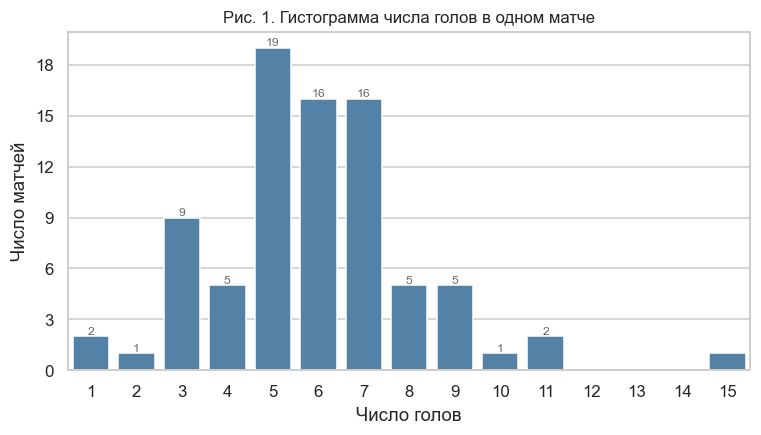

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))

lo, hi = int(games['Total Score'].min()), int(games['Total Score'].max())
sns.countplot(x=games['Total Score'], order=range(lo, hi + 1),
              color='steelblue', edgecolor='white', ax=ax)

ax.set_xlabel('Число голов')
ax.set_ylabel('Число матчей')
ax.set_title('Рис. 1. Гистограмма числа голов в одном матче')
ax.set_yticks(range(0, 19, 3))

for patch, value in zip(ax.patches, range(lo, hi + 1)):
    n = int((games['Total Score'] == value).sum())
    if n:
        ax.annotate(n, (patch.get_x() + patch.get_width() / 2, n),
                    ha='center', va='bottom', fontsize=8, color='dimgray')

fig.savefig(FIGDIR / 'fig01_total_score_hist.png')
plt.show()

**Комментарий.** Распределение одновершинное, с модой на 5 голах (19 матчей) и плотным
ядром 4–8 голов, в которое попадает **74 %** всех матчей. Форма типична для счётных
данных — распределение близко к пуассоновскому, но с двумя оговорками:

* **левый край обрезан**: матч не может закончиться 0 : 0, поэтому минимум равен 1
  (и такой счёт возможен только через овертайм);
* **правый хвост длиннее левого**: есть одинокий выброс на 15 голах при полном отсутствии
  значений 12–14. Это матч *Colorado Avalanche – Minnesota Wild (9 – 6)*, разобранный
  в следующем пункте.

Для сравнения ниже — пуассоновская аппроксимация с тем же средним. У распределения Пуассона
дисперсия равна среднему; здесь выборочная дисперсия (5.11) немного **меньше** среднего
(5.93), то есть данные чуть «собраннее» пуассоновских. Асимметрия при этом положительная
(skew = 0.78) — за счёт единственного матча с 15 голами, который лежит далеко в хвосте.

дисперсия выборки: 5.11   среднее: 5.93


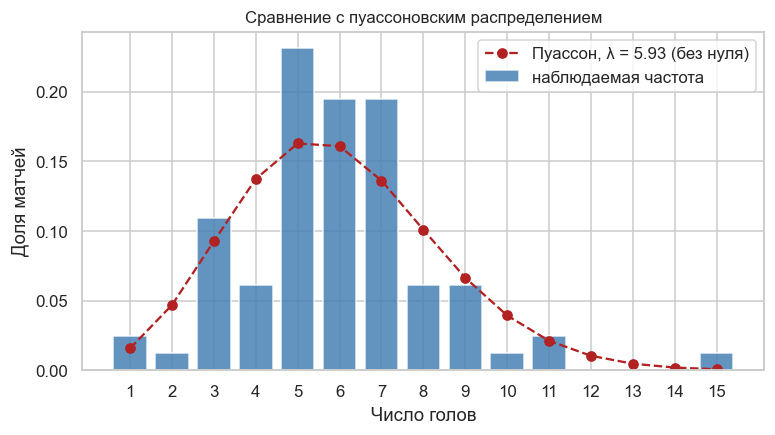

In [16]:
lam = games['Total Score'].mean()
k = np.arange(1, 16)
# P(X=k) для Пуассона, нормированная на P(X>=1), т. к. счёт 0:0 невозможен
logp = -lam + k * np.log(lam) - np.array([np.sum(np.log(np.arange(1, i + 1))) for i in k])
pois = np.exp(logp) / (1 - np.exp(-lam))

fig, ax = plt.subplots(figsize=(8, 4))
obs = games['Total Score'].value_counts().reindex(k, fill_value=0)
ax.bar(k, obs / len(games), color='steelblue', label='наблюдаемая частота', alpha=.85)
ax.plot(k, pois, 'o--', color='firebrick', label=f'Пуассон, λ = {lam:.2f} (без нуля)')
ax.set_xlabel('Число голов'); ax.set_ylabel('Доля матчей')
ax.set_title('Сравнение с пуассоновским распределением')
ax.set_xticks(k); ax.legend()
print(f"дисперсия выборки: {games['Total Score'].var():.2f}   среднее: {lam:.2f}")
fig.savefig(FIGDIR / 'fig01b_poisson.png')
plt.show()

---

## 6. Самые нерезультативные и самые результативные матчи

In [17]:
total = games['Total Score']
lowest  = [gameInfo(g) for g in games.index[total == total.min()]]
highest = [gameInfo(g) for g in games.index[total == total.max()]]

lowest

['Montréal Canadiens - Tampa Bay Lightning (0 - 1, Final/OT, 2026-05-01)',
 'Philadelphia Flyers - Pittsburgh Penguins (1 - 0, Final/OT, 2026-04-29)']

In [18]:
highest

['Colorado Avalanche - Minnesota Wild (9 - 6, Final, 2026-05-03)']

Оба списка совпадают с примерами из условия.

**Комментарий.** Два «минимальных» матча — это 1 : 0 в овертайме, то есть 60 минут основного
времени обе команды не могли забить вообще. Характерно, что оба случая произошли в первом
раунде (`Game ID` 2025030126 и 2025030146), где серии традиционно самые вязкие.

Единственный матч с 15 голами — *Colorado Avalanche – Minnesota Wild (9 – 6)*. Посмотрим на
десятку самых результативных матчей целиком, чтобы понять, насколько он одинок.

In [19]:
top10 = total.nlargest(10)
pd.DataFrame({'Game Info': [gameInfo(g) for g in top10.index],
              'Total Score': top10.values}, index=top10.index)

,Game Info,Total Score
Game ID,,
2025030231,"Colorado Avalanche - Minnesota Wild (9 - 6, Fi...",15
2025030183,"Anaheim Ducks - Edmonton Oilers (7 - 4, Final,...",11
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",11
2025030182,"Edmonton Oilers - Anaheim Ducks (4 - 6, Final,...",10
2025030174,"Utah Mammoth - Vegas Golden Knights (4 - 5, Fi...",9
2025030175,"Vegas Golden Knights - Utah Mammoth (5 - 4, Fi...",9
2025030215,"Buffalo Sabres - Montréal Canadiens (3 - 6, Fi...",9
2025030411,Carolina Hurricanes - Vegas Golden Knights (4 ...,9
2025030413,Vegas Golden Knights - Carolina Hurricanes (5 ...,9


Разрыв очевиден: 15 голов против 11 у следующего матча. Это действительно выброс, а не край
плотного хвоста.

---

## 7. Сколько игроков участвовало в матче

Берём все 14 полей «игроки на льду» (по шесть полевых плюс вратарь для каждой команды),
собираем уникальные фамилии по матчу и считаем их. Важная деталь: `pd.unique()` по объектному
массиву возвращает и `NaN`, поэтому пропуски нужно отбросить явно — иначе пустая ячейка
посчитается за «игрока».

In [20]:
def distinct_players(block):
    """Число различных фамилий среди полей «игроки на льду» в одном матче."""
    names = pd.unique(block.values.ravel())
    return int(pd.notna(names).sum())


player_count = events.groupby('Game ID')[ON_ICE].apply(distinct_players)
games['Player Count'] = player_count

top = player_count.nlargest(1)
pd.DataFrame({'Game Info': [gameInfo(g) for g in top.index],
              'Player Count': top.values}, index=top.index)

,Game Info,Player Count
Game ID,,
2025030216,"Montréal Canadiens - Buffalo Sabres (3 - 8, Fi...",40


Расхождение с примером в условии. В условии для этого матча указано 41 игрок, у нас — 40. Причина техническая: при подсчёте уникальных значений pd.unique() учитывает NaN как отдельное уникальное значение. Поэтому наивный подсчёт без удаления пропусков завышает число игроков на единицу. Лидер при этом не меняется.

In [21]:
naive = events.groupby('Game ID')[ON_ICE].apply(lambda b: len(pd.unique(b.values.ravel())))
diff = naive - player_count
print('разница «с NaN» минус «без NaN» по всем матчам:', diff.unique())
print('наивный подсчёт для матча 2025030216:', naive.loc[2025030216])
pd.DataFrame({'без NaN (верно)': player_count.nlargest(5),
              'с NaN (как в условии)': naive.nlargest(5)})

разница «с NaN» минус «без NaN» по всем матчам: [1]
наивный подсчёт для матча 2025030216: 41


,без NaN (верно),с NaN (как в условии)
Game ID,,
2025030216,40,41
2025030112,39,40
2025030114,39,40
2025030185,39,40
2025030215,39,40


Упорядочение матчей от способа подсчёта не зависит, и лидер тот же — поэтому содержательный
ответ на задание не меняется: больше всего игроков (**40**) участвовало в матче
*Montréal Canadiens – Buffalo Sabres (3 – 8)*. Дальше по тексту используется корректный
подсчёт без `NaN`.

Почему именно этот матч? Он закончился разгромом 8 : 3, а в таких играх тренеры проигрывающей
команды меняют вратаря и шире тасуют составы. Посмотрим на распределение и на связь с
разницей в счёте.

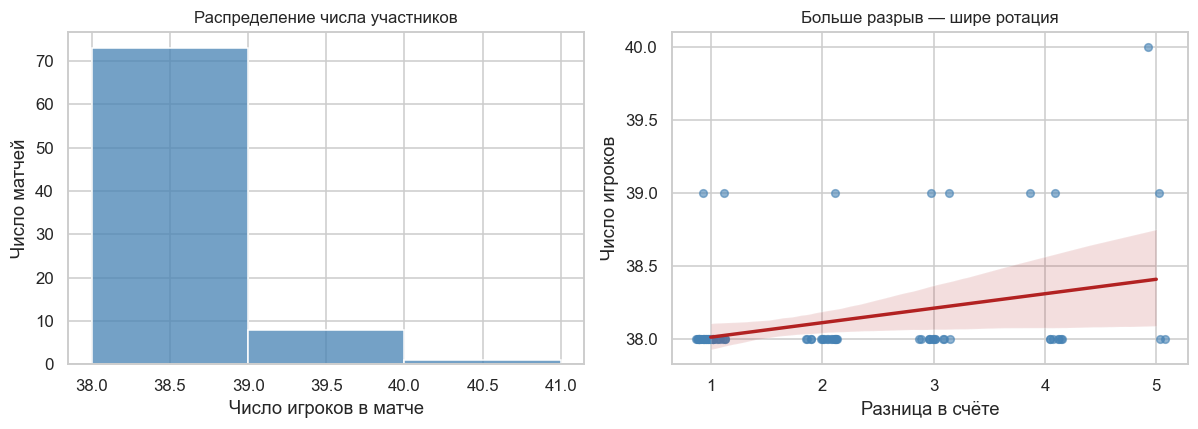

медиана: 38.0 | диапазон: 38 - 40
корреляция с разницей в счёте: 0.333


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(player_count, bins=range(int(player_count.min()), int(player_count.max()) + 2),
             color='steelblue', edgecolor='white', ax=axes[0])
axes[0].set_xlabel('Число игроков в матче'); axes[0].set_ylabel('Число матчей')
axes[0].set_title('Распределение числа участников')

games['Margin'] = (games['Home Score'] - games['Away Score']).abs()
sns.regplot(data=games, x='Margin', y='Player Count', ax=axes[1],
            x_jitter=.15, scatter_kws=dict(s=25, alpha=.6, color='steelblue'),
            line_kws=dict(color='firebrick'))
axes[1].set_xlabel('Разница в счёте'); axes[1].set_ylabel('Число игроков')
axes[1].set_title('Больше разрыв — шире ротация')

fig.tight_layout()
fig.savefig(FIGDIR / 'fig02_player_count.png')
plt.show()

print('медиана:', player_count.median(), '| диапазон:', player_count.min(), '-', player_count.max())
print('корреляция с разницей в счёте:', round(games[['Margin', 'Player Count']].corr().iloc[0, 1], 3))

Разброс крайне узкий: от **38** до **40** игроков при медиане 38, то есть примерно по 19–20
на команду — это и есть стандартная заявка (18 полевых + 2 вратаря). Связь с разницей в счёте
слабо положительная ($r = 0.33$): в «валидольных» матчах тренеры играют укороченной обоймой,
в разгромных — выпускают на лёд всех, включая второго вратаря.

---

## 8. Расстояние от точки броска до ворот

### Куда бьёт команда

Поле `Home Team's Defending Side` говорит, какие ворота в этом периоде защищают хозяева.
Отсюда получаем ворота, по которым бьёт автор события:

| бьют | хозяева защищают | атакуют ворота |
|------|------------------|----------------|
| хозяева | left  | $X = +89$ |
| хозяева | right | $X = -89$ |
| гости   | left  | $X = -89$ |
| гости   | right | $X = +89$ |

Таблица — это в точности «исключающее ИЛИ‑НЕ»: ворота справа ($+89$) тогда и только тогда,
когда признаки «бьют хозяева» и «хозяева защищают левые» **совпадают**.

### Формула расстояния

Ворота имеют длину 6 футов, то есть створ — это отрезок $y \in [-3, 3]$ при $x = X$.
Расстояние до ближайшей точки створа:

$$d(x,y) = \begin{cases}
\sqrt{(x-X)^2 + (y+3)^2}, & y < -3,\\
|x-X|, & -3 \leqslant y \leqslant 3,\\
\sqrt{(x-X)^2 + (y-3)^2}, & y > 3.
\end{cases}$$

Все три случая — это одна и та же формула $\sqrt{(x-X)^2 + \tilde y^2}$, где $\tilde y$ —
отклонение $y$ за пределы створа (и ноль внутри него). Поэтому хватает одного вызова
`np.hypot`, который к тому же численно устойчив.

In [23]:
GOAL_X, GOAL_HALF = 89.0, 3.0


def target_goal_x(df):
    """X-координата ворот, по которым бьёт команда из 'Team Making the Play'."""
    home_plays = df['Team Making the Play'] == df['Home Team']
    home_defends_left = df["Home Team's Defending Side"] == 'left'
    return np.where(home_plays == home_defends_left, GOAL_X, -GOAL_X)


def distance_to_goal(x, y, goal_x, half=GOAL_HALF):
    """Расстояние до ближайшей точки створа ворот (в футах)."""
    overshoot = np.clip(np.abs(y) - half, 0, None) * np.sign(y)
    return np.hypot(x - goal_x, overshoot)


shot_mask = events['Play Type'].isin(SHOTS)

events['Shot Length'] = np.nan
events.loc[shot_mask, 'Shot Length'] = distance_to_goal(
    events.loc[shot_mask, 'X Coordinate on the Ice Rink'].to_numpy(float),
    events.loc[shot_mask, 'Y Coordinate on the Ice Rink'].to_numpy(float),
    target_goal_x(events.loc[shot_mask]),
)

events[shot_mask][['Game ID', 'Play Type', 'Shot Length']]

,Game ID,Play Type,Shot Length
7,2025030111,missed-shot,12.207
9,2025030111,missed-shot,12.000
12,2025030111,missed-shot,29.411
13,2025030111,shot-on-goal,62.169
19,2025030111,missed-shot,52.924
...,...,...,...
29695,2025030416,missed-shot,54.083
29696,2025030416,missed-shot,5.099
29704,2025030416,goal,46.239
29706,2025030416,missed-shot,60.926


7 266 бросков, и значения в начале и в конце таблицы совпадают с примером из условия
до третьего знака.

Проверим формулу независимо — «в лоб», тремя ветвями `if`, на случайной подвыборке.

In [24]:
def distance_naive(x, y, X, half=GOAL_HALF):
    if y < -half:
        return ((x - X) ** 2 + (y + half) ** 2) ** .5
    if y > half:
        return ((x - X) ** 2 + (y - half) ** 2) ** .5
    return abs(x - X)


sample = events[shot_mask].sample(400, random_state=0)
gx = target_goal_x(sample)
naive_vals = [distance_naive(x, y, X) for x, y, X in zip(
    sample['X Coordinate on the Ice Rink'], sample['Y Coordinate on the Ice Rink'], gx)]

print('максимальное расхождение с векторной формулой:',
      np.abs(np.asarray(naive_vals) - sample['Shot Length'].to_numpy()).max())

максимальное расхождение с векторной формулой: 0.0


Расхождение нулевое. Ещё одна, уже содержательная проверка: зона, которую даёт геометрия
(синие линии на $x = \pm 25$), должна совпадать с записанным в данных полем `Play Zone`.
Это независимый контроль того, что направление атаки определено верно.

In [25]:
sh = events[shot_mask].copy()
# координата вдоль направления атаки: +89 — атакуемые ворота
sh['x toward goal'] = np.where(target_goal_x(sh) > 0,
                               sh['X Coordinate on the Ice Rink'],
                               -sh['X Coordinate on the Ice Rink'])
sh['Zone by geometry'] = pd.cut(sh['x toward goal'], [-200, -25, 25, 200],
                                labels=['Defensive', 'Neutral', 'Offensive'])
pd.crosstab(sh['Play Zone'], sh['Zone by geometry'])

Zone by geometry,Defensive,Neutral,Offensive
Play Zone,,,
Defensive,164,0,0
Neutral,0,206,0
Offensive,0,12,6884


Матрица практически диагональна: 6 884 из 6 896 броска из зоны атаки, все 164 броска из своей
зоны и все 206 из нейтральной классифицированы одинаково. Двенадцать расхождений — события
ровно на синей линии, где округление координаты до целого фута решает дело. Значит
направление атаки определено правильно, и `Shot Length` можно доверять.

In [26]:
events.loc[shot_mask, 'Shot Length'].describe()

count   7266.000
mean      35.409
std       27.471
min        0.000
25%       15.556
50%       31.898
75%       47.877
max      188.215
Name: Shot Length, dtype: float64

---

## 9. Распределение длины точных и неточных бросков

Подвыборки разного размера (4 623 точных против 2 643 неточных), поэтому абсолютные частоты
сравнивать нельзя — нужны **плотности**. В `seaborn.displot()` за это отвечают два аргумента:
`stat='density'` (нормировка на единичную площадь) и, что важнее, `common_norm=False` —
иначе `seaborn` нормирует обе гистограммы на один общий интеграл и большая группа опять
«задавит» меньшую.

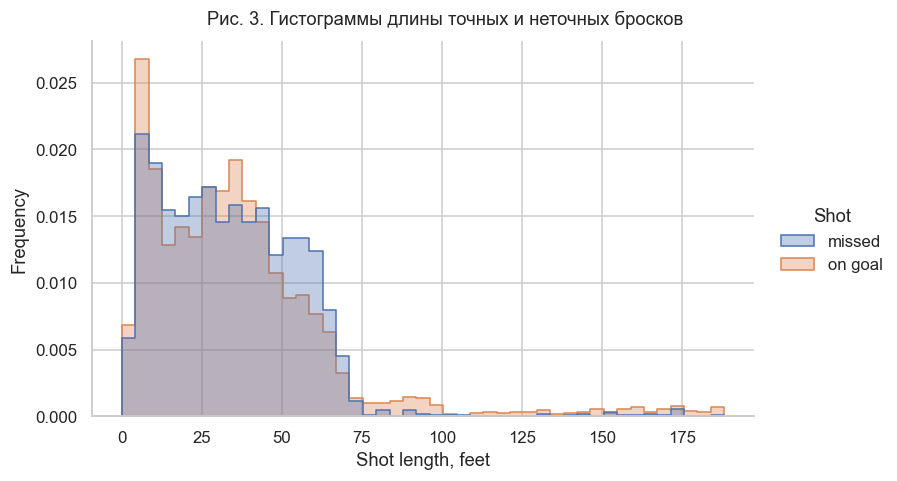

In [27]:
shots = events[shot_mask].copy()
shots['Shot'] = np.where(shots['Play Type'] == 'missed-shot', 'missed', 'on goal')

g = sns.displot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'],
                stat='density', common_norm=False, element='step', fill=True,
                alpha=.35, bins=45, height=4.2, aspect=1.7)
g.set_axis_labels('Shot length, feet', 'Frequency')
g.figure.suptitle('Рис. 3. Гистограммы длины точных и неточных бросков', y=1.03)
g.savefig(FIGDIR / 'fig03_shot_length.png')
plt.show()

In [28]:
shots.groupby('Shot')['Shot Length'].describe()

,count,mean,std,min,25%,50%,75%,max
Shot,,,,,,,,
missed,2643.000,34.014,22.313,0.000,16.155,32.249,49.041,185.068
on goal,4623.000,36.207,29.997,0.000,15.000,31.828,47.011,188.215


### Какой вывод можно сделать

Центральные части распределений почти неразличимы: медианы 31.8 фута у точных бросков против
32.3 у неточных, первый и третий квартили совпадают с точностью до фута. **Само расстояние
почти не определяет, попадёт ли бросок в створ** — на дистанции 10–50 футов доли точных и
неточных бросков меняются слабо.

Различия сосредоточены на краях:

* **вблизи ворот** (0–15 футов) плотность точных бросков заметно выше — с пятачка попасть
  в створ легко, и именно поэтому средняя длина точного броска (36.2) больше, чем неточного
  (34.0), несмотря на почти равные медианы: среднее тянет вверх правый хвост;
* **на дистанции 35–60 футов** плотность неточных бросков выше — это броски от синей линии,
  которые чаще летят мимо;
* у точных бросков есть **длинный хвост за 90 футов**, то есть со своей половины площадки,
  которого у неточных практически нет.

### Почему у точных бросков такой длинный хвост

Главная причина — **асимметрия регистрации событий**, а не физика броска. Проверим числами.

In [29]:
shots['Opp Goalie'] = np.where(shots['Team Making the Play'] == shots['Home Team'],
                               shots["Away Team's Goalie"], shots["Home Team's Goalie"])
shots['Empty Net'] = shots['Opp Goalie'].isna()

long_shots = shots[shots['Shot Length'] > 89]
print('броски со своей половины (> 89 футов):', len(long_shots), 'из', len(shots))
print()
print('доля длинных бросков внутри каждой группы:')
print((shots.groupby('Shot')['Shot Length'].apply(lambda s: (s > 89).mean()) * 100).round(2))
print()
print('доля бросков в пустые ворота среди длинных:')
print(long_shots.groupby('Shot')['Empty Net'].mean().round(3))
print()
print('записанная зона длинных бросков:')
print(long_shots['Play Zone'].value_counts())

броски со своей половины (> 89 футов): 251 из 7266

доля длинных бросков внутри каждой группы:
Shot
missed    1.140
on goal   4.780
Name: Shot Length, dtype: float64

доля бросков в пустые ворота среди длинных:
Shot
missed    0.767
on goal   0.014
Name: Empty Net, dtype: float64

записанная зона длинных бросков:
Play Zone
Defensive    164
Neutral       87
Name: count, dtype: int64


Числа складываются в такую картину:

1. **Асимметрия регистрации.** Среди точных бросков длинных — **4.78 %**, среди неточных —
   всего **1.14 %**, то есть в четыре с лишним раза меньше. Это артефакт протокола: шайба,
   выброшенная через всю площадку и дошедшая до вратаря, фиксируется как `shot-on-goal`,
   а такая же шайба, прошедшая мимо, обычно не попадает в протокол как бросок вовсе —
   она становится `stoppage` (проброс), `giveaway` или вбрасыванием. Длинные промахи просто
   не регистрируются, поэтому хвост виден почти только у точной группы.

2. **Пустые ворота.** Среди длинных *неточных* бросков **77 %** нанесены в пустые ворота
   (вратарь заменён шестым полевым) — при игре в большинстве в конце матча бросают с любой
   дистанции. Среди длинных *точных* таких лишь 1.4 %, что логично: если ворота пусты,
   «вратарь» поймать не может, так что событие либо гол, либо промах.

3. **Это не ошибка в данных.** Поле `Play Zone` для длинных бросков честно показывает
   `Defensive` (164) и `Neutral` (87) — данные внутренне согласованы, и такие броски
   действительно нанесены со своей половины. По сути это выбросы шайбы из своей зоны,
   которые протокол НХЛ классифицировал как броски.

Иначе говоря, длинный хвост у точных бросков — следствие того, **как считают броски**,
а не того, что кто‑то регулярно забивает через всю площадку.

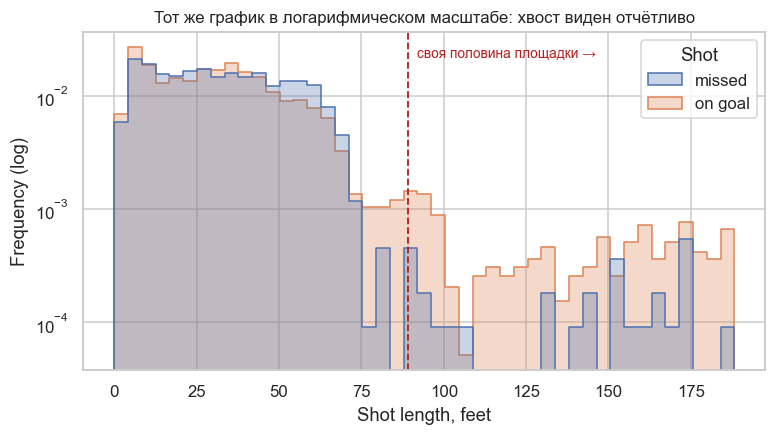

In [30]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=shots, x='Shot Length', hue='Shot', hue_order=['missed', 'on goal'],
             stat='density', common_norm=False, element='step', bins=45, alpha=.3, ax=ax)
ax.axvline(89, color='firebrick', ls='--', lw=1.2)
ax.annotate('своя половина площадки →', (92, .022), color='firebrick', fontsize=9)
ax.set_yscale('log')
ax.set_xlabel('Shot length, feet'); ax.set_ylabel('Frequency (log)')
ax.set_title('Тот же график в логарифмическом масштабе: хвост виден отчётливо')
fig.savefig(FIGDIR / 'fig03b_shot_length_log.png')
plt.show()

---

## 10. Доля точных бросков у каждой команды в каждом матче

Незаблокированные броски — это `shot-on-goal`, `goal` и `missed-shot`; точные из них —
первые два (гол ведь тоже попал в створ). Заблокированные броски (`blocked-shot`) по условию
не участвуют: они до ворот не доходят по причине, от бросавшего не зависящей.

In [31]:
unblocked = events[events['Play Type'].isin(SHOTS)]
grp = unblocked.groupby(['Game ID', 'Team Making the Play'])

numshots = pd.DataFrame({
    'Shots': grp.size(),
    'Shots on Goal': grp['Play Type'].apply(lambda s: s.isin(ACCURATE).sum()),
})
numshots['Share of Shots on Goal'] = numshots['Shots on Goal'] / numshots['Shots']

numshots['Share of Shots on Goal']

Game ID     Team Making the Play
2025030111  Boston Bruins          0.625
            Buffalo Sabres         0.679
2025030112  Boston Bruins          0.614
            Buffalo Sabres         0.636
2025030113  Boston Bruins          0.694
                                    ... 
2025030414  Vegas Golden Knights   0.583
2025030415  Carolina Hurricanes    0.558
            Vegas Golden Knights   0.510
2025030416  Carolina Hurricanes    0.639
            Vegas Golden Knights   0.595
Name: Share of Shots on Goal, Length: 164, dtype: float64

164 строки = 82 матча × 2 команды, и выборочные значения совпадают с условием.

**Какой вывод можно сделать.** Доля точных бросков держится в удивительно узком коридоре.
Посмотрим на её распределение.

count   164.000
mean      0.639
std       0.085
min       0.353
25%       0.583
50%       0.639
75%       0.689
max       0.860

доля наблюдений в коридоре 0.5-0.8: 0.927


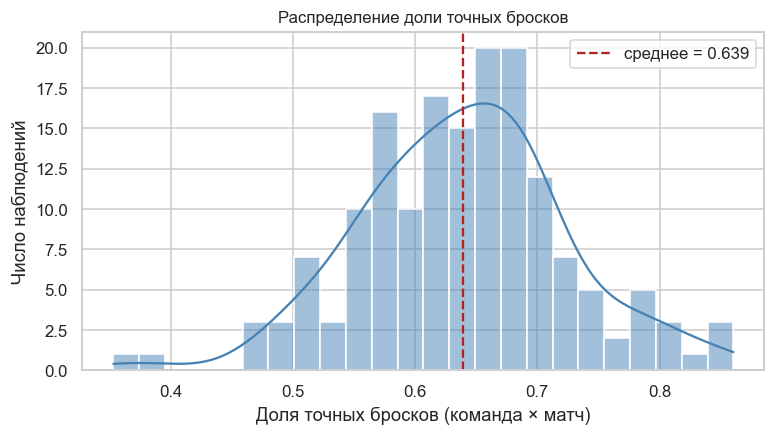

In [32]:
share = numshots['Share of Shots on Goal']
print(share.describe().round(3).to_string())
print()
print('доля наблюдений в коридоре 0.5-0.8:', round(share.between(.5, .8).mean(), 3))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(share, bins=24, color='steelblue', edgecolor='white', kde=True, ax=ax)
ax.axvline(share.mean(), color='firebrick', ls='--',
           label=f'среднее = {share.mean():.3f}')
ax.set_xlabel('Доля точных бросков (команда × матч)')
ax.set_ylabel('Число наблюдений')
ax.set_title('Распределение доли точных бросков')
ax.legend()
fig.savefig(FIGDIR / 'fig04_share_hist.png')
plt.show()

Среднее — **0.639**, то есть примерно **две трети** незаблокированных бросков достигают створа,
и 93 % наблюдений лежат между 0.5 и 0.8. Распределение симметричное, одновершинное, без
тяжёлых хвостов — это похоже на биномиальный шум вокруг общего для лиги уровня, а не на
смесь «точных» и «неточных» команд.

Проверим это прямо: если различия между командами реальны, то дисперсия средних по командам
должна быть заметно больше той, что даёт случайность. Сравним фактический разброс командных
средних с разбросом при случайном перемешивании ярлыков команд.

In [33]:
rng = np.random.default_rng(0)
team_means = share.groupby('Team Making the Play').mean()
observed_sd = team_means.std()

labels = share.index.get_level_values('Team Making the Play').to_numpy()
vals = share.to_numpy()
null_sd = np.array([
    pd.Series(vals, index=rng.permutation(labels)).groupby(level=0).mean().std()
    for _ in range(2000)
])

p = (null_sd >= observed_sd).mean()
print(f'разброс командных средних: {observed_sd:.4f}')
print(f'при случайных ярлыках:     {null_sd.mean():.4f} (ст. откл. {null_sd.std():.4f})')
print(f'p-value перестановочного теста: {p:.3f}')

разброс командных средних: 0.0345
при случайных ярлыках:     0.0299 (ст. откл. 0.0058)
p-value перестановочного теста: 0.210


Наблюдаемый разброс командных средних (0.0345) лишь немного превышает случайный (0.0299),
и $p = 0.21$ — гипотезу о том, что команды по этому показателю **неразличимы**, отклонить
нельзя. То есть доля точных бросков — характеристика лиги (≈ 2/3), а не индивидуальный навык
команды. Содержательный вывод для следующего пункта: верхушку и низ рейтинга стоит трактовать
с осторожностью.

---

## 11. Команды с самой высокой и самой низкой средней долей точных бросков

In [34]:
avgnumshots = share.groupby('Team Making the Play').mean()
avgnumshots.nlargest(5)

Team Making the Play
Edmonton Oilers       0.706
Philadelphia Flyers   0.684
Dallas Stars          0.670
Minnesota Wild        0.656
Colorado Avalanche    0.653
Name: Share of Shots on Goal, dtype: float64

In [35]:
avgnumshots.nsmallest(5)

Team Making the Play
Pittsburgh Penguins   0.554
Utah Mammoth          0.599
Carolina Hurricanes   0.615
Tampa Bay Lightning   0.626
Buffalo Sabres        0.626
Name: Share of Shots on Goal, dtype: float64

Оба списка совпадают с условием.

**Комментарий.** Весь разброс командных средних — от 0.554 у «Питтсбурга» до 0.706 у
«Эдмонтона», то есть **15 процентных пунктов** между лучшим и худшим, а между 2‑м и 15‑м
местом — всего 8.5. При 4–22 матчах на команду это сопоставимо со случайной погрешностью,
что подтвердил перестановочный тест выше.

Отдельно обращает на себя внимание, что рейтинг **не связан с успехом в плей‑офф**:
«Эдмонтон» с лучшей точностью провёл всего 6 матчей (вылетел в первом раунде), а «Каролина»,
взявшая Кубок, стоит третьей **снизу** (0.615). Точность броска и победы — разные вещи.

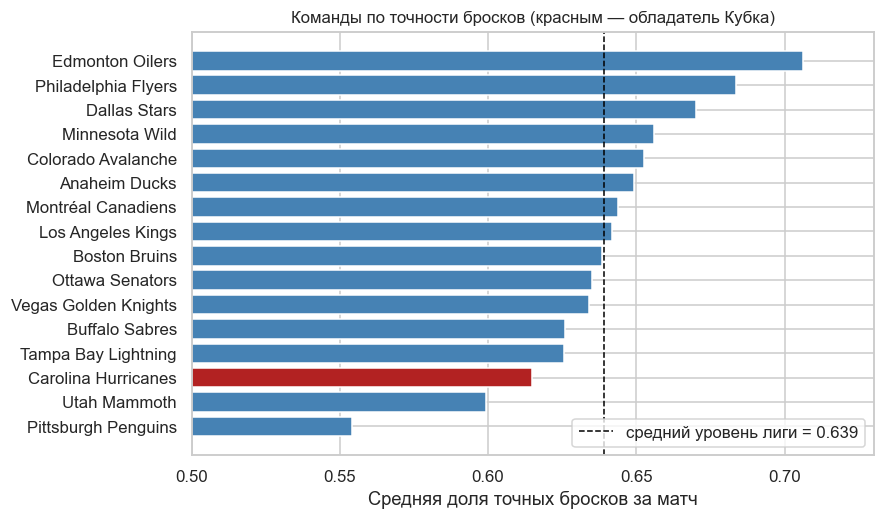

,Share of Shots on Goal,Games Played,Rank
Edmonton Oilers,0.706,6,1
Philadelphia Flyers,0.684,10,2
Dallas Stars,0.670,6,3
Minnesota Wild,0.656,11,4
Colorado Avalanche,0.653,13,5
Anaheim Ducks,0.649,12,6
Montréal Canadiens,0.644,19,7
Los Angeles Kings,0.642,4,8
Boston Bruins,0.638,6,9
Ottawa Senators,0.635,4,10


In [36]:
games_played = pd.concat([games['Away Team'], games['Home Team']]).value_counts()

ranking = pd.DataFrame({
    'Share of Shots on Goal': avgnumshots,
    'Games Played': games_played,
}).sort_values('Share of Shots on Goal', ascending=False)
ranking['Rank'] = range(1, len(ranking) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['firebrick' if t == 'Carolina Hurricanes' else 'steelblue' for t in ranking.index]
ax.barh(ranking.index, ranking['Share of Shots on Goal'], color=colors)
ax.axvline(share.mean(), color='black', ls='--', lw=1,
           label=f'средний уровень лиги = {share.mean():.3f}')
ax.set_xlim(.5, .73)
ax.invert_yaxis()
ax.set_xlabel('Средняя доля точных бросков за матч')
ax.set_title('Команды по точности бросков (красным — обладатель Кубка)')
ax.legend(loc='lower right')
fig.savefig(FIGDIR / 'fig05_team_accuracy.png')
plt.show()

ranking

---

## 12. Среднее число бросков в створ и голов за игру

«Бросок в створ ворот» — это `shot-on-goal` **и** `goal`: забитая шайба тоже попала в створ.
Делим на число матчей, проведённых командой (от 4 у «Оттавы» до 22 у «Вегаса»).

In [37]:
shots_goals = (events[events['Play Type'].isin(ACCURATE)]
               .pivot_table(index='Team Making the Play', columns='Play Type',
                            aggfunc='size', fill_value=0))

avgshots = pd.DataFrame({
    'Shot': shots_goals.sum(axis=1) / games_played,   # shot-on-goal + goal
    'Goal': shots_goals['goal'] / games_played,
}).sort_index()
avgshots.index.name = 'Team Making the Play'

avgshots

,Shot,Goal
Team Making the Play,,
Anaheim Ducks,31.667,3.250
Boston Bruins,25.167,2.000
Buffalo Sabres,30.462,3.308
Carolina Hurricanes,31.632,3.474
Colorado Avalanche,32.154,3.385
Dallas Stars,31.000,2.500
Edmonton Oilers,28.333,3.500
Los Angeles Kings,25.250,1.250
Minnesota Wild,28.727,3.727


Все 32 числа совпадают с примером из условия.

**Комментарий.** Среднее по лиге — около **28 бросков** и **2.7 гола** за матч, то есть
реализация примерно **10.5 %** (486 голов на 4 623 броска в створ). Разброс по броскам —
от 23.3 у «Монреаля» до 32.2 у «Колорадо»
(в 1.4 раза), по голам — от 1.25 у «Лос‑Анджелеса» и «Оттавы» до 3.7 у «Миннесоты»
(почти в 3 раза). Голы варьируются сильнее, чем броски, — первый намёк на то, что объём
бросков объясняет результативность лишь частично.

In [38]:
summary = avgshots.copy()
summary['Games Played'] = games_played
summary['Conversion, %'] = 100 * summary['Goal'] / summary['Shot']
summary.sort_values('Conversion, %', ascending=False)

,Shot,Goal,Games Played,"Conversion, %"
Team Making the Play,,,,
Vegas Golden Knights,26.545,3.455,22,13.014
Minnesota Wild,28.727,3.727,11,12.975
Edmonton Oilers,28.333,3.500,6,12.353
Montréal Canadiens,23.263,2.842,19,12.217
Carolina Hurricanes,31.632,3.474,19,10.982
Buffalo Sabres,30.462,3.308,13,10.859
Utah Mammoth,27.833,3.000,6,10.778
Colorado Avalanche,32.154,3.385,13,10.526
Anaheim Ducks,31.667,3.250,12,10.263


---

## 13. Связь числа бросков и числа голов

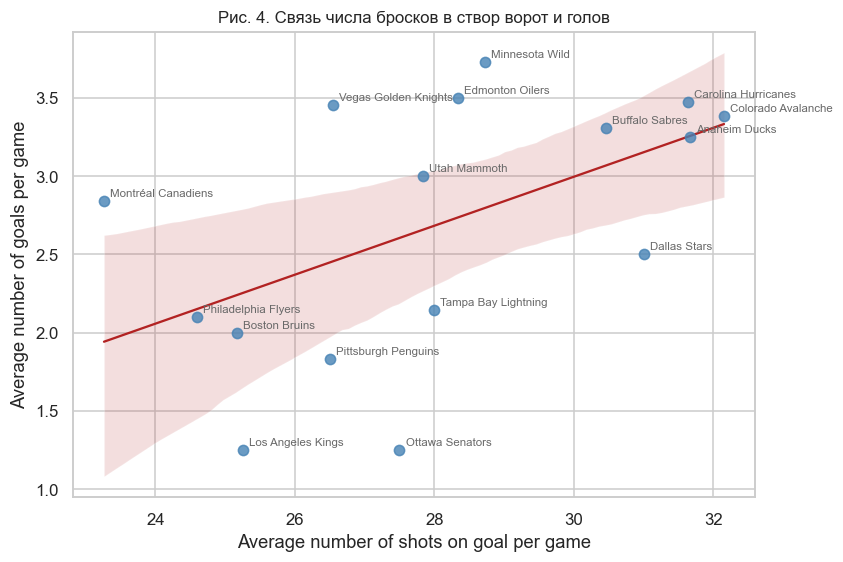

In [39]:
fig, ax = plt.subplots(figsize=(8, 5.5))

sns.regplot(data=avgshots, x='Shot', y='Goal', ax=ax,
            scatter_kws=dict(s=45, color='steelblue', zorder=3),
            line_kws=dict(color='firebrick', lw=1.5))

for team, row in avgshots.iterrows():
    ax.annotate(team, (row['Shot'], row['Goal']), fontsize=7.5, color='dimgray',
                xytext=(4, 3), textcoords='offset points')

ax.set_xlabel('Average number of shots on goal per game')
ax.set_ylabel('Average number of goals per game')
ax.set_title('Рис. 4. Связь числа бросков в створ ворот и голов')
fig.savefig(FIGDIR / 'fig06_regplot.png')
plt.show()

Линия регрессии идёт вверх, облако точек довольно широкое. Оценим связь численно:
коэффициент корреляции Пирсона и перестановочный тест его значимости (перестановочный, чтобы
не тянуть зависимость от `scipy` и не опираться на нормальность при $n = 16$).

In [40]:
def perm_corr(a, b, n=20_000, seed=42):
    """Корреляция Пирсона и p-value перестановочного теста (двусторонний)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    r = np.corrcoef(a, b)[0, 1]
    rng = np.random.default_rng(seed)
    null = np.array([np.corrcoef(a, rng.permutation(b))[0, 1] for _ in range(n)])
    return r, (np.abs(null) >= abs(r)).mean()


r_obs, p_value = perm_corr(avgshots['Shot'], avgshots['Goal'])
slope, intercept = np.polyfit(avgshots['Shot'], avgshots['Goal'], 1)

print(f'коэффициент корреляции Пирсона r = {r_obs:.3f}')
print(f'доля объяснённой дисперсии    R² = {r_obs ** 2:.3f}')
print(f'p-value (перестановочный тест)   = {p_value:.3f}   (20 000 перестановок)')
print(f'наклон: +1 бросок за матч → {slope:+.3f} гола за матч')

коэффициент корреляции Пирсона r = 0.521
доля объяснённой дисперсии    R² = 0.271
p-value (перестановочный тест)   = 0.042   (20 000 перестановок)
наклон: +1 бросок за матч → +0.156 гола за матч


### Видна связь или нет

**Связь видна, но она умеренная.** Корреляция положительная, $r = 0.521$, и знак
соответствует здравому смыслу: больше бросаешь — больше забиваешь. Численно:

* $p = 0.042$ — на уровне значимости 5 % гипотезу об отсутствии связи **можно отклонить**
  (хотя на уровне 1 % — уже нет);
* $R^2 = 0.271$ — объёмом бросков объясняется **27 %** различий в результативности,
  а остальные **73 %** приходятся на всё прочее: реализацию, игру вратарей, качество позиций;
* наклон: каждый дополнительный бросок в створ за матч даёт в среднем **+0.16 гола**, то есть
  примерно один дополнительный гол на шесть дополнительных бросков — что близко к общей
  реализации по лиге (10.5 %).

Главная оговорка — объём выборки: всего 16 точек. Проверим устойчивость оценки, пересчитав
корреляцию с исключением по одной команде (jackknife).

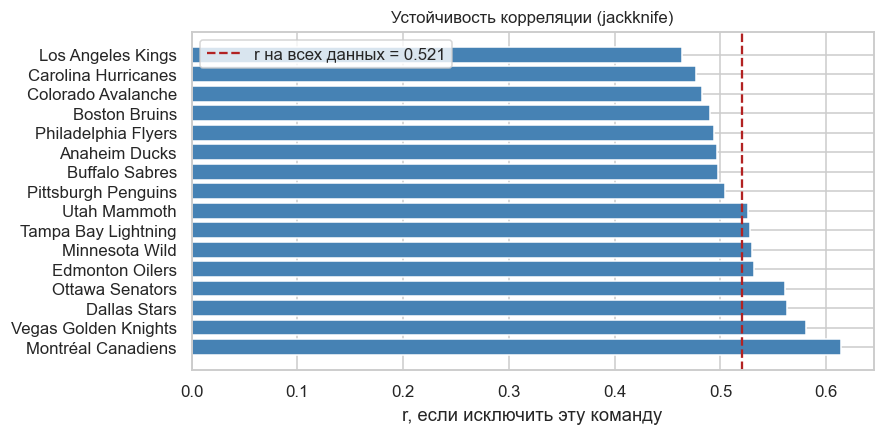

r меняется от 0.464 до 0.614


In [41]:
jack = pd.Series({
    team: np.corrcoef(avgshots.drop(team)['Shot'], avgshots.drop(team)['Goal'])[0, 1]
    for team in avgshots.index
}).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(jack.index, jack.values, color='steelblue')
ax.axvline(r_obs, color='firebrick', ls='--', label=f'r на всех данных = {r_obs:.3f}')
ax.invert_yaxis()
ax.set_xlabel('r, если исключить эту команду')
ax.set_title('Устойчивость корреляции (jackknife)')
ax.legend()
fig.savefig(FIGDIR / 'fig06b_jackknife.png')
plt.show()

print(f'r меняется от {jack.min():.3f} до {jack.max():.3f}')

Корреляция остаётся в диапазоне **0.46–0.61**, то есть знак и порядок величины не зависят от
какой‑либо одной команды — оценка устойчива. Наибольшее влияние оказывает «Монреаль»
(минимум бросков при средней результативности) — без него связь только усиливается.

Итого: связь есть и она положительная, но объясняет лишь четверть различий. Естественный
вопрос — что составляет остальные три четверти? Логично предположить, что дело в *качестве*
бросковых позиций: бросок с пятачка и бросок от синей линии — совсем не одно и то же.
Эту гипотезу мы и проверим в п. 22.

---

## 14. Матч с наибольшим числом ударов по воротам

Считаем все четыре типа: `shot-on-goal`, `goal`, `missed-shot` и `blocked-shot`.

In [42]:
attempts = events[events['Play Type'].isin(ATTEMPTS)].groupby('Game ID').size()
idxmax = attempts.idxmax()

print('ударов:', attempts.max())
gameInfo(idxmax)

ударов: 208


'Carolina Hurricanes - Ottawa Senators (3 - 2, Final/2OT, 2026-04-20)'

Совпадает с условием. Посмотрим на десятку лидеров и на структуру ударов в матче‑рекордсмене.

In [43]:
top_attempts = attempts.nlargest(10)
pd.DataFrame({'Game Info': [gameInfo(g) for g in top_attempts.index],
              'Attempts': top_attempts.values,
              'Periods': games.loc[top_attempts.index, 'Outcome'].values}, index=top_attempts.index)

,Game Info,Attempts,Periods
Game ID,,,
2025030132,"Carolina Hurricanes - Ottawa Senators (3 - 2, ...",208,Final/2OT
2025030164,"Minnesota Wild - Dallas Stars (3 - 2, Final/OT...",169,Final/OT
2025030413,Vegas Golden Knights - Carolina Hurricanes (5 ...,163,Final/2OT
2025030126,Montréal Canadiens - Tampa Bay Lightning (0 - ...,156,Final/OT
2025030175,"Vegas Golden Knights - Utah Mammoth (5 - 4, Fi...",154,Final/2OT
2025030174,"Utah Mammoth - Vegas Golden Knights (4 - 5, Fi...",152,Final/OT
2025030152,"Colorado Avalanche - Los Angeles Kings (2 - 1,...",151,Final/OT
2025030217,"Buffalo Sabres - Montréal Canadiens (2 - 3, Fi...",151,Final/OT
2025030163,"Minnesota Wild - Dallas Stars (3 - 4, Final/2O...",148,Final/2OT


In [44]:
best_game = events[(events['Game ID'] == idxmax) & events['Play Type'].isin(ATTEMPTS)]
pd.crosstab(best_game['Team Making the Play'], best_game['Play Type'],
            margins=True, margins_name='Всего')

Play Type,blocked-shot,goal,missed-shot,shot-on-goal,Всего
Team Making the Play,,,,,
Carolina Hurricanes,26,3,34,46,109
Ottawa Senators,28,2,32,37,99
Всего,54,5,66,83,208


208 ударов — это следствие двух овертаймов: матч продлился 5 периодов вместо 3. Ровно так же
устроены и остальные лидеры списка — **все десять** матчей первой десятки закончились
овертаймом. Нормировав на период, рекорд выглядит скромнее.

In [45]:
periods_played = events.groupby('Game ID')['Period'].max()
per_period = (attempts / periods_played).nlargest(5)
pd.DataFrame({'Game Info': [gameInfo(g) for g in per_period.index],
              'Attempts': attempts.loc[per_period.index].values,
              'Periods': periods_played.loc[per_period.index].values,
              'Attempts per period': per_period.values}, index=per_period.index)

,Game Info,Attempts,Periods,Attempts per period
Game ID,,,,
2025030112,"Buffalo Sabres - Boston Bruins (2 - 4, Final, ...",141,3,47.000
2025030314,Montréal Canadiens - Carolina Hurricanes (0 - ...,140,3,46.667
2025030151,"Colorado Avalanche - Los Angeles Kings (2 - 1,...",138,3,46.000
2025030181,"Edmonton Oilers - Anaheim Ducks (4 - 3, Final,...",138,3,46.000
2025030171,"Vegas Golden Knights - Utah Mammoth (4 - 2, Fi...",135,3,45.000


В пересчёте на период самым «настрелянным» оказывается уже другой матч — то есть рекорд
п. 14 объясняется в основном длительностью игры, а не её сверхинтенсивностью.

---

## 15. Карта ударов по воротам в матче‑рекордсмене

Чтобы броски обеих команд не накладывались, приводим площадку к единой ориентации:
**хозяева атакуют правые ворота, гости — левые**. Хозяева атакуют правые тогда, когда
защищают левые, поэтому отражать $(x, y) \mapsto (-x, -y)$ нужно в тех периодах, где
`Home Team's Defending Side == 'right'`.

> В условии предложено отражать координаты «в нечётных периодах». Для этого матча правила
> совпадают — здесь хозяева защищают правые ворота именно в периодах 1, 3, 5. Но в целом по
> выборке это не универсально: в 31 матче из 82 хозяева в первом периоде защищают левые
> ворота, и правило по номеру периода дало бы зеркальную картинку. Поэтому используем
> признак `Home Team's Defending Side` — он корректен для любого матча.

In [46]:
check = (events[events['Game ID'] == idxmax]
         .groupby('Period')["Home Team's Defending Side"].first())
print('матч-рекордсмен — сторона защиты хозяев по периодам:')
print(check.to_string())

p1 = events[events['Period'] == 1].groupby('Game ID')["Home Team's Defending Side"].first()
print('\nпо всей выборке, сторона защиты хозяев в 1-м периоде:')
print(p1.value_counts().to_string())

матч-рекордсмен — сторона защиты хозяев по периодам:
Period
1    right
2     left
3    right
4     left
5    right

по всей выборке, сторона защиты хозяев в 1-м периоде:
Home Team's Defending Side
right    51
left     31


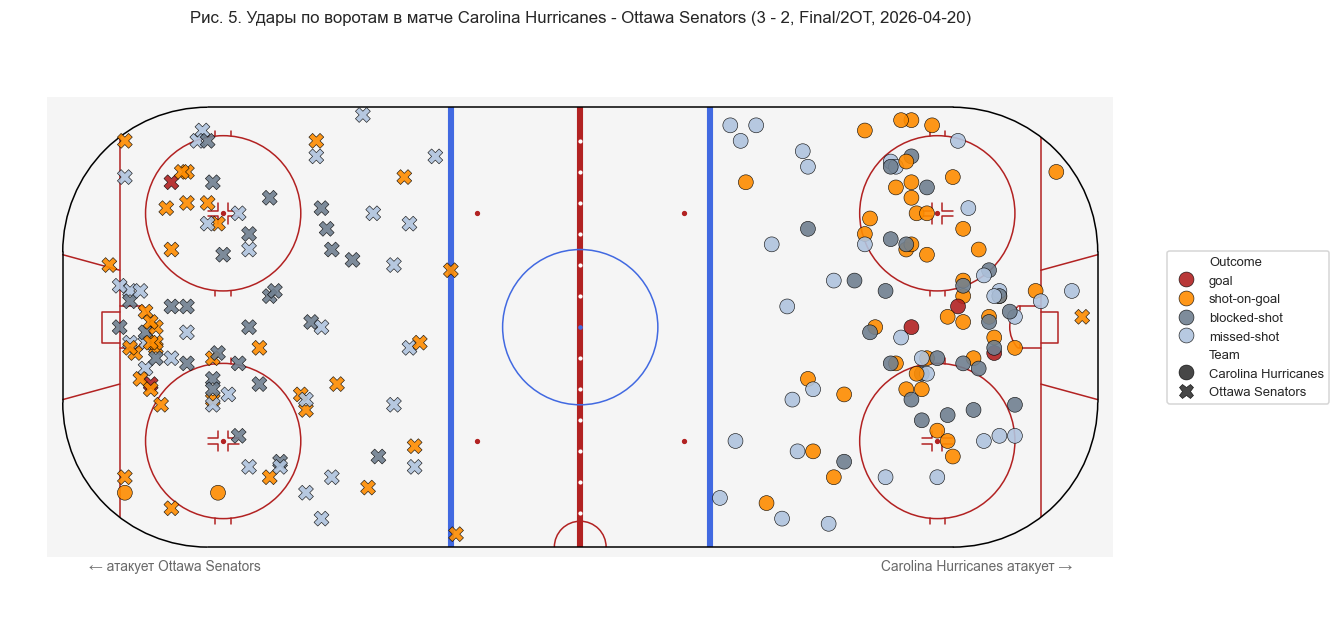

In [47]:
from rink import plot_rink

shot_map = events[(events['Game ID'] == idxmax)
                  & events['Play Type'].isin(ATTEMPTS)].copy()

flip = (shot_map["Home Team's Defending Side"] == 'right').to_numpy()
shot_map['X plot'] = np.where(flip, -shot_map['X Coordinate on the Ice Rink'],
                              shot_map['X Coordinate on the Ice Rink'])
shot_map['Y plot'] = np.where(flip, -shot_map['Y Coordinate on the Ice Rink'],
                              shot_map['Y Coordinate on the Ice Rink'])

home, away = games.loc[idxmax, 'Home Team'], games.loc[idxmax, 'Away Team']
shot_map['Team'] = shot_map['Team Making the Play']
shot_map['Outcome'] = shot_map['Play Type']   # чтобы легенда называлась как на рис. 5

fig = plt.figure(figsize=(12, 5.6))
plot_rink()

sns.scatterplot(data=shot_map, x='X plot', y='Y plot',
                hue='Outcome',
                hue_order=['goal', 'shot-on-goal', 'blocked-shot', 'missed-shot'],
                palette={'goal': 'firebrick', 'shot-on-goal': 'darkorange',
                         'blocked-shot': 'slategray', 'missed-shot': 'lightsteelblue'},
                style='Team', style_order=[home, away],
                markers={home: 'o', away: 'X'},
                s=95, edgecolor='black', linewidth=.4, alpha=.9, zorder=3)

plt.axis('equal')
plt.axis('off')
plt.title(f'Рис. 5. Удары по воротам в матче {gameInfo(idxmax)}', y=1.0)
plt.annotate(f'← атакует {away}', (-95, -47), fontsize=9, color='dimgray')
plt.annotate(f'{home} атакует →', (95, -47), fontsize=9, color='dimgray', ha='right')
plt.legend(loc='center left', bbox_to_anchor=(1.01, .5), frameon=True, fontsize=8.5)
plt.tight_layout(pad=.1)
fig.savefig(FIGDIR / 'fig07_shot_map.png')
plt.show()

> **Про код из условия.** В приведённом в задании фрагменте два вызова в современном
> `matplotlib` приводят к ошибке: `plt.axis('even')` — такого режима нет (нужен `'equal'`),
> и `plt.tight_layout(0.1)` — позиционный аргумент больше не принимается (нужен
> `pad=0.1`). Выше использованы исправленные варианты.

**Что видно на карте.** Удары плотно концентрируются в «домике» перед воротами и у кругов
вбрасывания — классическая картина. Заблокированные броски (серые) ложатся ближе к воротам,
чем броски в створ: защитник подставляет корпус на пути шайбы, и в протоколе фиксируется
точка блока, а не точка броска (числа — в таблице ниже). Пять голов (красные) забиты
из непосредственной близости от створа, тогда
как промахи (светлые) рассеяны по всей зоне атаки, включая дальние точки. Это ровно та связь
«расстояние → вероятность гола», которую мы количественно оценим в п. 22.

Посчитаем дистанции по типам удара. Обратим внимание: в п. 8 поле `Shot Length` по условию
заполнялось только для трёх типов бросков, поэтому для заблокированных его нужно посчитать
отдельно — формула и правило выбора ворот те же.

In [48]:
shot_map['Distance'] = distance_to_goal(
    shot_map['X Coordinate on the Ice Rink'].to_numpy(float),
    shot_map['Y Coordinate on the Ice Rink'].to_numpy(float),
    target_goal_x(shot_map),
)

zone_stats = shot_map.groupby('Play Type')['Distance'].agg(['size', 'mean', 'median']).round(2)
zone_stats.columns = ['Ударов', 'Среднее расстояние', 'Медиана']
zone_stats.loc['Всего'] = [len(shot_map), shot_map['Distance'].mean().round(2),
                           shot_map['Distance'].median().round(2)]
zone_stats

,Ударов,Среднее расстояние,Медиана
Play Type,,,
blocked-shot,54.000,25.480,27.390
goal,5.000,17.440,16.030
missed-shot,66.000,35.840,38.060
shot-on-goal,83.000,34.040,27.800
Всего,208.000,31.990,28.460


Числа подтверждают картинку: голы забиты в среднем с **17 футов**, тогда как промахи и броски
в створ — примерно с 34–36.

Отдельно стоит прокомментировать заблокированные броски: у них среднее расстояние **25.5
фута**, то есть *меньше*, чем у бросков в створ. Это не значит, что блокируют только броски
с близкой дистанции — скорее всего, в данных записана точка, где шайбу **заблокировали**,
а она по определению лежит между бросающим и воротами, то есть ближе к ним. На карте это
видно: серые точки образуют дугу перед «домиком» — там, где защитники подставляют корпус,
а не там, откуда был сделан бросок.

---

# Индивидуальная статистика (пп. 16–21)

Дальше понадобится число матчей, проведённых каждым игроком, — это знаменатель для средних
в пп. 19–20. Считаем матч проведённым, если фамилия игрока встречается хотя бы в одном
событии в полях «игроки на льду» (включая вратарскую позицию).

In [49]:
on_ice_long = pd.concat([
    events[['Game ID', col]].rename(columns={col: 'Player'})
    for col in ON_ICE
]).dropna().drop_duplicates()

games_by_player = on_ice_long.groupby('Player')['Game ID'].nunique().rename('GP')

print('игроков в выборке:', len(games_by_player))
print('матчей у игрока: от', games_by_player.min(), 'до', games_by_player.max())
games_by_player.describe().to_frame().T

игроков в выборке: 372
матчей у игрока: от 1 до 22


,count,mean,std,min,25%,50%,75%,max
GP,372.000,8.403,5.651,1.000,4.000,6.000,12.000,22.000


Проверим, что фамилии в полях событий и в полях «игроки на льду» согласованы: любой участник
события должен быть в этот момент на льду.

In [50]:
event_players = pd.unique(events[[f'Player in the Event #{i}' for i in (1, 2, 3)]].values.ravel())
event_players = {p for p in event_players if isinstance(p, str)}
unknown = event_players - set(games_by_player.index)
print('участников событий, ни разу не найденных на льду:', len(unknown))
print('всего различных участников событий:', len(event_players))

участников событий, ни разу не найденных на льду: 0
всего различных участников событий: 367


---

## 16. Десять лучших снайперов

Автор гола — `Player in the Event #1` у событий типа `goal`.

In [51]:
goals = events[events['Play Type'] == 'goal']
goal_scorers = goals['Player in the Event #1'].value_counts().rename('Goals')
goal_scorers.head(10).to_frame()

,Goals
Player in the Event #1,
Brett Howden,14
Pavel Dorofeyev,12
Logan Stankoven,11
Mitch Marner,10
Nikolaj Ehlers,8
Jordan Staal,8
Nathan MacKinnon,7
Taylor Hall,7
Alex Newhook,7


**Brett Howden** (Vegas Golden Knights) — лучший снайпер плей‑офф с 14 голами; «Вегас» дошёл
до финала и провёл 22 матча, что дало его игрокам больше всего возможностей.

Важная оговорка: на нижней границе списка — ничья, и `head(10)` обрезает её произвольно.
Выведем всех, кто попал бы в десятку по значению.

In [52]:
cut = goal_scorers.iloc[9]
tied = goal_scorers[goal_scorers == cut]
print(f'на 10-й позиции {cut} голов, и столько же у {len(tied)} игроков:')
print(', '.join(tied.index))

на 10-й позиции 7 голов, и столько же у 6 игроков:
Nathan MacKinnon, Taylor Hall, Alex Newhook, Matt Boldy, Jackson Blake, Mark Stone


То есть «список из десяти» здесь не определён однозначно: 10‑е место делят шесть игроков
с 7 голами. Ниже, в пп. 18–20, та же оговорка действует и для других рейтингов.

## 17. Десять лучших по голевым передачам

Ассистенты — поля `Player in the Event #2` (первая передача) и `#3` (вторая) у голов.

In [53]:
assists = (pd.concat([goals['Player in the Event #2'], goals['Player in the Event #3']])
           .dropna().value_counts().rename('Assists'))
assists.head(10).to_frame()

,Assists
Jack Eichel,20
Mitch Marner,19
Jackson Blake,13
Lane Hutson,13
Shea Theodore,12
Taylor Hall,12
Nick Suzuki,12
Martin Necas,12
Kirill Kaprizov,11
Quinn Hughes,11


Из 486 голов первую передачу имеют почти все, вторую — существенно меньше; посмотрим точно.

In [54]:
pd.Series({
    'голов всего': len(goals),
    'с первой передачей': goals['Player in the Event #2'].notna().sum(),
    'со второй передачей': goals['Player in the Event #3'].notna().sum(),
    'без передач (соло)': goals['Player in the Event #2'].isna().sum(),
}).to_frame('количество')

,количество
голов всего,486
с первой передачей,459
со второй передачей,371
без передач (соло),27


## 18. Десять лучших по системе «гол плюс пас»

In [55]:
points = pd.DataFrame({
    'Goals': goal_scorers,
    'Assists': assists,
}).reindex(sorted(set(goal_scorers.index) | set(assists.index))).fillna(0).astype(int)
points['Points'] = points['Goals'] + points['Assists']
points.index.name = 'Player'

top_points = points.sort_values(['Points', 'Goals'], ascending=False).head(10)
top_points

,Goals,Assists,Points
Player,,,
Mitch Marner,10,19,29
Jack Eichel,2,20,22
Jackson Blake,7,13,20
Taylor Hall,7,12,19
Brett Howden,14,4,18
Nikolaj Ehlers,8,10,18
Shea Theodore,6,12,18
Pavel Dorofeyev,12,4,16
Logan Stankoven,11,5,16


**Mitch Marner** — лучший бомбардир плей‑офф: 29 очков (10 + 19). Обратим внимание на разные
профили: Marner и Eichel набирают очки прежде всего передачами (19 и 20 соответственно), тогда
как Howden — чистый снайпер (14 + 4).

Здесь ничья на границе тоже есть: 16 очков набрали четыре игрока, а в десятку по сортировке
попадают три из них — вне списка остаётся **Lane Hutson** (3 + 13). Добавим клубы и число
матчей, чтобы картина была полной.

In [56]:
player_team = (pd.concat([
    events[['Team Making the Play', 'Player in the Event #1']]
        .rename(columns={'Player in the Event #1': 'Player'}),
]).dropna().groupby('Player')['Team Making the Play']
  .agg(lambda s: s.value_counts().idxmax()).rename('Team'))

detailed = top_points.join(player_team).join(games_by_player)
detailed['Points per game'] = (detailed['Points'] / detailed['GP']).round(2)
detailed[['Team', 'GP', 'Goals', 'Assists', 'Points', 'Points per game']]

,Team,GP,Goals,Assists,Points,Points per game
Player,,,,,,
Mitch Marner,Vegas Golden Knights,22,10,19,29,1.320
Jack Eichel,Vegas Golden Knights,22,2,20,22,1.000
Jackson Blake,Carolina Hurricanes,19,7,13,20,1.050
Taylor Hall,Carolina Hurricanes,19,7,12,19,1.000
Brett Howden,Vegas Golden Knights,22,14,4,18,0.820
Nikolaj Ehlers,Carolina Hurricanes,18,8,10,18,1.000
Shea Theodore,Vegas Golden Knights,22,6,12,18,0.820
Pavel Dorofeyev,Vegas Golden Knights,22,12,4,16,0.730
Logan Stankoven,Carolina Hurricanes,19,11,5,16,0.840


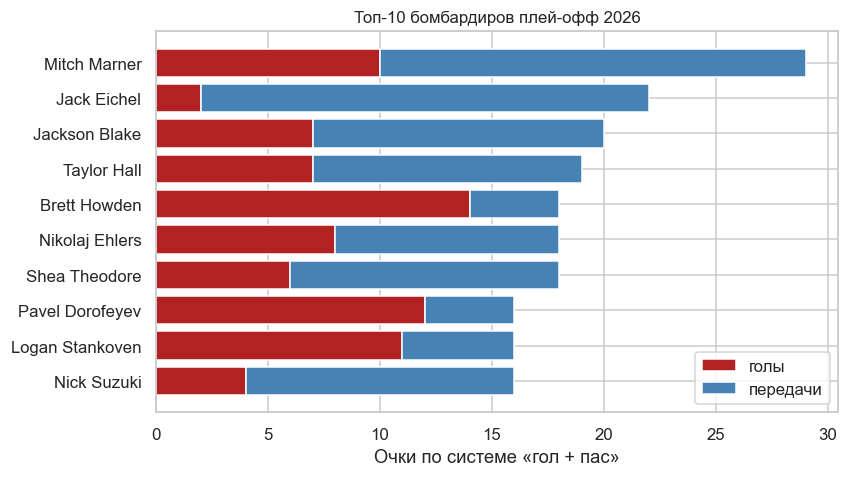

In [57]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = top_points.iloc[::-1]
ax.barh(plot_df.index, plot_df['Goals'], color='firebrick', label='голы')
ax.barh(plot_df.index, plot_df['Assists'], left=plot_df['Goals'],
        color='steelblue', label='передачи')
ax.set_xlabel('Очки по системе «гол + пас»')
ax.set_title('Топ-10 бомбардиров плей-офф 2026')
ax.legend(loc='lower right')
fig.savefig(FIGDIR / 'fig08_top_scorers.png')
plt.show()

---

## 19. Десять игроков с лучшим средним числом бросков в створ за матч

Бросок в створ — события `shot-on-goal` и `goal`, автор в `Player in the Event #1`.
Делим на число матчей игрока.

Здесь есть методическая тонкость: у игрока, проведшего один матч, среднее оценено крайне
ненадёжно — один удачный вечер выводит его в лидеры. Поэтому приводим и формальный рейтинг,
и рейтинг с разумным порогом по числу матчей.

In [58]:
sog = events[events['Play Type'].isin(ACCURATE)]['Player in the Event #1'].value_counts()

shots_per_game = pd.DataFrame({'Shots on Goal': sog, 'GP': games_by_player}).dropna()
shots_per_game['GP'] = shots_per_game['GP'].astype(int)
shots_per_game['Shots on Goal'] = shots_per_game['Shots on Goal'].astype(int)
shots_per_game['per game'] = shots_per_game['Shots on Goal'] / shots_per_game['GP']
shots_per_game.index.name = 'Player'

shots_per_game.sort_values('per game', ascending=False).head(10)

,Shots on Goal,GP,per game
Player,,,
Jason Robertson,30,6,5.000
Dylan Guenther,27,6,4.500
Nikita Kucherov,31,7,4.429
Matt Boldy,48,11,4.364
Quinton Byfield,17,4,4.250
Darren Raddysh,28,7,4.000
Joel Eriksson Ek,24,6,4.000
Alex Laferriere,15,4,3.750
David Pastrnak,22,6,3.667


Формальный лидер — **Jason Robertson** (5.00 броска за матч при 6 играх). В верхушке нет
игроков с одним‑двумя матчами, так что список устойчив. Для надёжности — тот же рейтинг с
порогом «не менее 8 матчей» (примерно полтора раунда).

In [59]:
reliable = shots_per_game[shots_per_game['GP'] >= 8].sort_values('per game', ascending=False)
reliable.head(10).join(player_team)

,Shots on Goal,GP,per game,Team
Player,,,,
Matt Boldy,48,11,4.364,Minnesota Wild
Nathan MacKinnon,47,13,3.615,Colorado Avalanche
Tage Thompson,46,13,3.538,Buffalo Sabres
Alex Tuch,46,13,3.538,Buffalo Sabres
Rasmus Dahlin,46,13,3.538,Buffalo Sabres
Leo Carlsson,41,12,3.417,Anaheim Ducks
Cutter Gauthier,39,12,3.250,Anaheim Ducks
Ryan Hartman,35,11,3.182,Minnesota Wild
Taylor Hall,55,19,2.895,Carolina Hurricanes


## 20. Десять игроков с лучшим средним числом силовых приёмов за матч

Силовой приём — `Play Type == 'hit'`, его выполняет `Player in the Event #1`
(поле `#2` — тот, против кого приём применён).

In [60]:
hits = events[events['Play Type'] == 'hit']['Player in the Event #1'].value_counts()

hits_per_game = pd.DataFrame({'Hits': hits, 'GP': games_by_player}).dropna()
hits_per_game['GP'] = hits_per_game['GP'].astype(int)
hits_per_game['Hits'] = hits_per_game['Hits'].astype(int)
hits_per_game['per game'] = hits_per_game['Hits'] / hits_per_game['GP']
hits_per_game.index.name = 'Player'

hits_per_game.sort_values('per game', ascending=False).head(10)

,Hits,GP,per game
Player,,,
Lawson Crouse,38,6,6.333
Alex Turcotte,6,1,6.000
Alexander Petrovic,6,1,6.000
Yakov Trenin,51,9,5.667
Dylan Cozens,22,4,5.500
Vasily Podkolzin,32,6,5.333
Marcus Foligno,55,11,5.000
Ivan Barbashev,110,22,5.000
Carl Grundstrom,15,3,5.000


А вот здесь проблема малых выборок проявляется в полный рост: **Alex Turcotte** и
**Alexander Petrovic** попадают в топ‑10 с 6 приёмами в **единственном** матче. Сравним с
рейтингом по тому же порогу в 8 матчей.

In [61]:
hits_reliable = hits_per_game[hits_per_game['GP'] >= 8].sort_values('per game', ascending=False)
hits_reliable.head(10).join(player_team)

,Hits,GP,per game,Team
Player,,,,
Yakov Trenin,51,9,5.667,Minnesota Wild
Marcus Foligno,55,11,5.000,Minnesota Wild
Ivan Barbashev,110,22,5.000,Vegas Golden Knights
William Carrier,91,19,4.789,Carolina Hurricanes
Cole Smith,100,22,4.545,Vegas Golden Knights
Jordan Staal,86,19,4.526,Carolina Hurricanes
Jeffrey Truchon-Viel,51,12,4.250,Anaheim Ducks
Garnet Hathaway,33,8,4.125,Philadelphia Flyers
Travis Konecny,41,10,4.100,Philadelphia Flyers


С порогом картина меняется: лидером становится **Yakov Trenin** («Миннесота», 5.67 приёма за
матч в 9 играх), а случайные однодневки исчезают. Отдельно стоит отметить
**Ivan Barbashev** («Вегас»): 5.0 приёма за матч, но на дистанции **22 матчей** — это
абсолютный максимум по объёму (110 силовых приёмов), и такая величина уже точно не случайна.
Ниже видно, как разброс средних сжимается с ростом числа матчей — наглядная иллюстрация того,
почему средние по малым выборкам нельзя сравнивать напрямую.

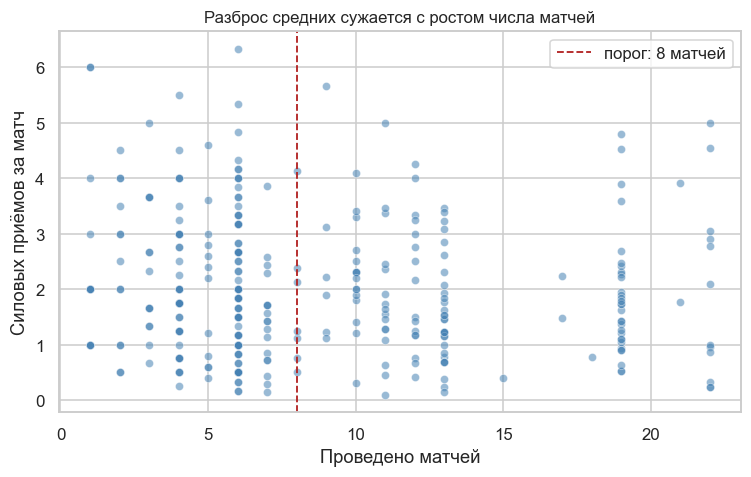

In [62]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=hits_per_game, x='GP', y='per game', ax=ax,
                s=28, alpha=.55, color='steelblue')
ax.axvline(8, color='firebrick', ls='--', lw=1.2, label='порог: 8 матчей')
ax.set_xlabel('Проведено матчей'); ax.set_ylabel('Силовых приёмов за матч')
ax.set_title('Разброс средних сужается с ростом числа матчей')
ax.legend()
fig.savefig(FIGDIR / 'fig09_hits_shrinkage.png')
plt.show()

---

## 21. Вратари, не пропустившие ни одного гола хотя бы в одном матче

Логика такая:

1. **Выходы вратарей.** Пара (матч, вратарь) берётся из полей `Away/Home Team's Goalie` —
   если фамилия встречается хотя бы в одном событии, вратарь в этом матче играл.
2. **Пропущенные голы.** У события `goal` гол пропускает вратарь **команды‑соперника**
   того, кто забил, и именно тот, кто в этот момент записан на льду. Это автоматически
   учитывает замены: голы делятся между вратарями по моменту их пропуска.
3. «Сухой» выход — пара (матч, вратарь) с нулём пропущенных.

По условию учитываем и неполные матчи — выходы на замену и случаи, когда вратаря заменили.

In [63]:
appearances = pd.concat([
    (events[['Game ID', "Away Team's Goalie", 'Away Team']]
     .dropna(subset=["Away Team's Goalie"])
     .rename(columns={"Away Team's Goalie": 'Goalie', 'Away Team': 'Team'})),
    (events[['Game ID', "Home Team's Goalie", 'Home Team']]
     .dropna(subset=["Home Team's Goalie"])
     .rename(columns={"Home Team's Goalie": 'Goalie', 'Home Team': 'Team'})),
]).drop_duplicates().set_index(['Game ID', 'Goalie'])

home_scored = goals['Team Making the Play'] == goals['Home Team']
conceded_by = pd.DataFrame({
    'Game ID': goals['Game ID'],
    'Goalie': np.where(home_scored, goals["Away Team's Goalie"], goals["Home Team's Goalie"]),
    'Team': np.where(home_scored, goals['Away Team'], goals['Home Team']),
})

ga = (conceded_by.dropna(subset=['Goalie'])
      .groupby(['Game ID', 'Goalie']).size().rename('GA'))

appearances['GA'] = ga.reindex(appearances.index).fillna(0).astype(int)

print('выходов вратарей (матч × вратарь):', len(appearances))
print('различных вратарей:', appearances.index.get_level_values('Goalie').nunique())
print('голов без вратаря на льду:', conceded_by['Goalie'].isna().sum(), 'из', len(goals))

выходов вратарей (матч × вратарь): 174
различных вратарей: 25
голов без вратаря на льду: 25 из 486


25 голов из 486 не удаётся отнести ни к одному вратарю — в этих строках поля вратарей пусты.
Разберёмся, что это за голы, прежде чем считать «сухие» матчи.

In [64]:
unattributed = conceded_by[conceded_by['Goalie'].isna()].index
ua = goals.loc[unattributed]
side_players = np.where(ua['Team Making the Play'] == ua['Home Team'],
                        ua["# of Away Team's Players on the Ice"],
                        ua["# of Home Team's Players on the Ice"])

print('по периодам:')
print(ua['Period'].value_counts().sort_index().to_string())
print('\nполевых игроков у пропускающей команды в этот момент:')
print(pd.Series(side_players).value_counts().sort_index().to_string())
print('\nовертаймных матчей в выборке:',
      int(games['Outcome'].str.contains('OT').sum()))

по периодам:
Period
3     3
4    18
5     4

полевых игроков у пропускающей команды в этот момент:
0    22
6     3

овертаймных матчей в выборке: 22


Картина совершенно ясная:

* **22 гола** забиты в периодах 4–5, и в этих строках нет вообще никакой информации о составах
  (ноль игроков на льду у обеих команд). Овертаймных матчей в выборке ровно 22 — то есть
  **у каждого победного гола в овертайме данные о составах не записаны**. Это системный пропуск
  в выгрузке, а не пустые ворота.
* Остальные **3 гола** — в третьем периоде, при шести полевых игроках и отсутствии вратаря:
  это настоящие голы в пустые ворота, и их действительно не следует вешать на вратаря.

Поэтому «сухие» выходы считаем двумя способами: формально (как написано в условии) и строго —
исключая матчи, где у команды вратаря есть неотнесённые голы.

In [65]:
shutouts = appearances[appearances['GA'] == 0].reset_index()

# неотнесённые голы в разрезе «матч × пропускающая команда»
ua_by_team = (conceded_by[conceded_by['Goalie'].isna()]
              .groupby(['Game ID', 'Team']).size().rename('Unattributed GA'))
shutouts['Unattributed GA'] = (
    ua_by_team.reindex(pd.MultiIndex.from_arrays(
        [shutouts['Game ID'], shutouts['Team']])).fillna(0).astype(int).to_numpy())

# итоговый счёт команды вратаря «в минус»
conceded_total = pd.concat([
    games.set_index([games.index, 'Home Team'])['Away Score'],
    games.set_index([games.index, 'Away Team'])['Home Score'],
])
shutouts['Team Conceded'] = conceded_total.reindex(
    pd.MultiIndex.from_arrays([shutouts['Game ID'], shutouts['Team']])).to_numpy()

shutouts['Game Info'] = [gameInfo(g) for g in shutouts['Game ID']]
shutouts = shutouts.sort_values(['Goalie', 'Game ID'])
shutouts[['Game ID', 'Goalie', 'Team', 'GA', 'Unattributed GA', 'Team Conceded', 'Game Info']]

,Game ID,Goalie,Team,GA,Unattributed GA,Team Conceded,Game Info
0,2025030126,Andrei Vasilevskiy,Tampa Bay Lightning,0,0,0,Montréal Canadiens - Tampa Bay Lightning (0 - ...
2,2025030146,Arturs Silovs,Pittsburgh Penguins,0,1,1,Philadelphia Flyers - Pittsburgh Penguins (1 -...
4,2025030413,Brandon Bussi,Carolina Hurricanes,0,1,5,Vegas Golden Knights - Carolina Hurricanes (5 ...
5,2025030416,Brandon Bussi,Carolina Hurricanes,0,0,0,Vegas Golden Knights - Carolina Hurricanes (0 ...
1,2025030142,Dan Vladar,Philadelphia Flyers,0,0,0,Pittsburgh Penguins - Philadelphia Flyers (0 -...
9,2025030146,Dan Vladar,Philadelphia Flyers,0,0,0,Philadelphia Flyers - Pittsburgh Penguins (1 -...
8,2025030131,Frederik Andersen,Carolina Hurricanes,0,0,0,"Carolina Hurricanes - Ottawa Senators (2 - 0, ..."
10,2025030221,Frederik Andersen,Carolina Hurricanes,0,0,0,Carolina Hurricanes - Philadelphia Flyers (3 -...
3,2025030314,Frederik Andersen,Carolina Hurricanes,0,0,0,Montréal Canadiens - Carolina Hurricanes (0 - ...
7,2025030126,Jakub Dobes,Montréal Canadiens,0,1,1,Montréal Canadiens - Tampa Bay Lightning (0 - ...


### Формальный ответ (как в условии)

Вратари, у которых есть хотя бы один матч без пропущенных голов:

In [66]:
formal = (shutouts.groupby('Goalie')
          .agg(**{'Team': ('Team', 'first'),
                  'Сухих выходов': ('Game ID', 'size')})
          .sort_values('Сухих выходов', ascending=False))
print('всего вратарей:', len(formal))
formal

всего вратарей: 8


,Team,Сухих выходов
Goalie,,
Frederik Andersen,Carolina Hurricanes,3
Brandon Bussi,Carolina Hurricanes,2
Dan Vladar,Philadelphia Flyers,2
Andrei Vasilevskiy,Tampa Bay Lightning,1
Arturs Silovs,Pittsburgh Penguins,1
Jakub Dobes,Montréal Canadiens,1
Joonas Korpisalo,Boston Bruins,1
Scott Wedgewood,Colorado Avalanche,1


### Строгий ответ (с поправкой на пропуск данных об овертаймах)

Исключаем выходы, в которых у команды вратаря есть неотнесённые голы: формально у вратаря ноль
пропущенных, но его команда в этом матче была пробита — просто протокол не говорит, кем именно
гол пропущен.

In [67]:
strict = shutouts[shutouts['Unattributed GA'] == 0]
strict_tbl = (strict.groupby('Goalie')
              .agg(**{'Team': ('Team', 'first'),
                      'Сухих выходов': ('Game ID', 'size')})
              .sort_values('Сухих выходов', ascending=False))
print('всего вратарей:', len(strict_tbl))
strict_tbl

всего вратарей: 6


,Team,Сухих выходов
Goalie,,
Frederik Andersen,Carolina Hurricanes,3
Dan Vladar,Philadelphia Flyers,2
Andrei Vasilevskiy,Tampa Bay Lightning,1
Brandon Bussi,Carolina Hurricanes,1
Joonas Korpisalo,Boston Bruins,1
Scott Wedgewood,Colorado Avalanche,1


In [68]:
excluded = shutouts[shutouts['Unattributed GA'] > 0]
excluded[['Game ID', 'Goalie', 'Team', 'Team Conceded', 'Unattributed GA', 'Game Info']]

,Game ID,Goalie,Team,Team Conceded,Unattributed GA,Game Info
2,2025030146,Arturs Silovs,Pittsburgh Penguins,1,1,Philadelphia Flyers - Pittsburgh Penguins (1 -...
4,2025030413,Brandon Bussi,Carolina Hurricanes,5,1,Vegas Golden Knights - Carolina Hurricanes (5 ...
7,2025030126,Jakub Dobes,Montréal Canadiens,1,1,Montréal Canadiens - Tampa Bay Lightning (0 - ...


**Вывод по пункту.** Формально «сухие» матчи есть у **8** вратарей (12 выходов). Три из этих
выходов — артефакт пропуска данных: «Питтсбург» Силовша, «Монреаль» Добеша и «Каролина» Бусси
в соответствующих матчах голы пропустили, просто победный гол в овертайме не отнесён к
вратарю. После поправки остаётся **6 вратарей** и **9 сухих выходов** (Силовс и Добеш
выпадают полностью, у Бусси остаётся один выход из двух).

Отдельного внимания заслуживают два содержательно разных случая:

* **Frederik Andersen** («Каролина») — 3 сухих матча, больше всех; это и есть вратарская
  основа команды, выигравшей Кубок.
* **Joonas Korpisalo** («Бостон», матч 2025030114) — пример из условия про неполную игру:
  «Бостон» пропустил в той встрече 6 голов, но все они на счету Джереми Свэймана, а Корпизало
  вышел на замену и не пропустил ни одного. Проверим это явно.

In [69]:
relief = events[(events['Game ID'] == 2025030114)]
print('вратари «Бостона» в матче:', relief["Home Team's Goalie"].dropna().unique())
relief[relief['Play Type'] == 'goal'][
    ['Period', 'Elapsed Time', 'Team Making the Play', "Home Team's Goalie"]
]

вратари «Бостона» в матче: ['Jeremy Swayman' 'Joonas Korpisalo']


,Period,Elapsed Time,Team Making the Play,Home Team's Goalie
1143,1,04:17,Buffalo Sabres,Jeremy Swayman
1153,1,07:10,Buffalo Sabres,Jeremy Swayman
1167,1,09:15,Buffalo Sabres,Jeremy Swayman
1198,1,14:24,Buffalo Sabres,Jeremy Swayman
1368,3,05:08,Buffalo Sabres,Jeremy Swayman
1376,3,06:32,Buffalo Sabres,Jeremy Swayman
1456,3,19:20,Boston Bruins,Joonas Korpisalo


Данные подтверждают: первые шесть голов «Баффало» пропустил Свэйман, после чего Корпизало
отыграл остаток матча на ноль. Именно такие случаи условие и просило учесть.

---

## 22. Собственное исследование

### Вопрос

> **Что важнее для результативности — сколько бросков команда наносит или откуда она их
> наносит? И как именно вероятность гола зависит от расстояния до ворот?**

Вопрос возник из п. 13: объём бросков объяснил лишь 27 % различий в результативности команд.
Естественная гипотеза — остальное объясняется **качеством** бросковых позиций: бросок
с пятачка и бросок от синей линии имеют совершенно разные шансы. Теперь у нас есть
`Shot Length` для каждого броска, так что гипотезу можно проверить.

Исследование разбивается на три шага:

1. построить **кривую опасности** — вероятность гола как функцию расстояния;
2. выяснить, **насколько команды различаются** по качеству позиций;
3. сравнить, что **лучше предсказывает** голы — объём бросков или их средняя дистанция.

### Шаг 1. Вероятность гола в зависимости от расстояния

Берём все незаблокированные броски и считаем в каждом интервале дистанции долю тех,
что стали голами.

In [70]:
shots_q = events[shot_mask].copy()
edges = [0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 80, 200]
# include_lowest=True обязательно: иначе два броска с нулевого расстояния
# (из-за округления координат до целого фута) выпали бы из разбиения
shots_q['Distance bin'] = pd.cut(shots_q['Shot Length'], edges, include_lowest=True)

conversion = shots_q.groupby('Distance bin', observed=True).agg(
    Shots=('Play Type', 'size'),
    Goals=('Play Type', lambda s: (s == 'goal').sum()),
)
conversion['Goal %'] = 100 * conversion['Goals'] / conversion['Shots']
# нормальное приближение 95 %-го интервала для доли
p_hat = conversion['Goals'] / conversion['Shots']
conversion['± 95 %'] = 100 * 1.96 * np.sqrt(p_hat * (1 - p_hat) / conversion['Shots'])

assert conversion['Shots'].sum() == shot_mask.sum(), 'потеряны броски при разбиении'
assert conversion['Goals'].sum() == (events['Play Type'] == 'goal').sum()
conversion

,Shots,Goals,Goal %,± 95 %
Distance bin,,,,
"(-0.001, 5.0]",334,50,14.970,3.826
"(5.0, 10.0]",883,96,10.872,2.053
"(10.0, 15.0]",559,59,10.555,2.547
"(15.0, 20.0]",520,45,8.654,2.417
"(20.0, 25.0]",511,43,8.415,2.407
"(25.0, 30.0]",617,51,8.266,2.173
"(30.0, 40.0]",1237,68,5.497,1.270
"(40.0, 50.0]",977,28,2.866,1.046
"(50.0, 60.0]",759,17,2.240,1.053


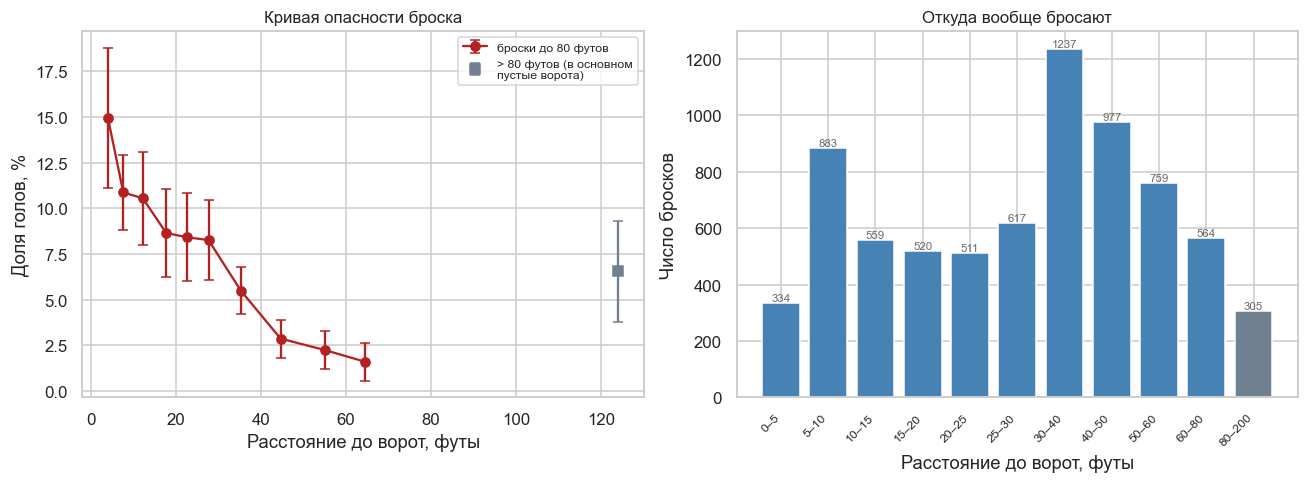

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# по оси X — медиана фактических расстояний внутри интервала, а не середина
# интервала: последний интервал (80–200) очень широкий, и середина ввела бы в заблуждение
centers = shots_q.groupby('Distance bin', observed=True)['Shot Length'].median().to_numpy()

axes[0].errorbar(centers[:-1], conversion['Goal %'][:-1], yerr=conversion['± 95 %'][:-1],
                 fmt='o-', color='firebrick', capsize=3, lw=1.5,
                 label='броски до 80 футов')
axes[0].errorbar(centers[-1:], conversion['Goal %'][-1:], yerr=conversion['± 95 %'][-1:],
                 fmt='s', color='slategray', capsize=3, ms=7,
                 label='> 80 футов (в основном\nпустые ворота)')
axes[0].set_xlabel('Расстояние до ворот, футы')
axes[0].set_ylabel('Доля голов, %')
axes[0].set_title('Кривая опасности броска')
axes[0].legend(fontsize=8)

labels = [f'{int(a)}–{int(b)}' for a, b in zip(edges[:-1], edges[1:])]
bars = axes[1].bar(range(len(conversion)), conversion['Shots'],
                   color=['steelblue'] * (len(conversion) - 1) + ['slategray'])
axes[1].set_xticks(range(len(conversion)))
axes[1].set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
axes[1].set_xlabel('Расстояние до ворот, футы')
axes[1].set_ylabel('Число бросков')
axes[1].set_title('Откуда вообще бросают')
axes[1].bar_label(bars, fontsize=7.5, color='dimgray')

fig.tight_layout()
fig.savefig(FIGDIR / 'fig10_conversion_curve.png')
plt.show()

**Результат первого шага.** Зависимость сильная и монотонная почти на всём диапазоне:

* с пятачка (0–5 футов) голом становится **≈ 15 %** бросков;
* с 15–20 футов — около **8.7 %**, то есть почти вдвое меньше;
* с 40–60 футов — **2–3 %**;
* с 60–80 футов — **1.6 %**, то есть **в 9 раз** хуже, чем с пятачка.

Подъём в последнем интервале (> 80 футов, ≈ 6.6 %) — это уже знакомый нам эффект пустых
ворот и бросков через всю площадку: там мало бросков и особая природа ситуаций, поэтому
содержательно этот интервал из тренда выбивается.

При этом правый график показывает любопытное: **команды бросают в основном не оттуда, где
опаснее**. Самый населённый интервал — 30–40 футов (1 237 бросков), где реализация уже
втрое ниже пятачковой. Причина понятна — на пятачок просто не пускают.

### Шаг 2. Различаются ли команды по качеству позиций

In [72]:
team_quality = shots_q.groupby('Team Making the Play').agg(
    **{'Бросков': ('Shot Length', 'size'),
       'Средняя дистанция': ('Shot Length', 'mean'),
       'Медиана': ('Shot Length', 'median')})
team_quality['Доля с ≤ 20 футов, %'] = (
    100 * shots_q.groupby('Team Making the Play')['Shot Length'].apply(lambda s: (s <= 20).mean()))
team_quality = team_quality.join(avgshots).sort_values('Средняя дистанция')
team_quality

,Бросков,Средняя дистанция,Медиана,"Доля с ≤ 20 футов, %",Shot,Goal
Team Making the Play,,,,,,
Buffalo Sabres,630,32.680,30.741,35.556,30.462,3.308
Montréal Canadiens,682,33.476,28.089,36.804,23.263,2.842
Ottawa Senators,178,33.669,29.983,33.708,27.500,1.250
Vegas Golden Knights,933,34.279,29.411,35.048,26.545,3.455
Tampa Bay Lightning,314,34.455,34.518,25.478,28.000,2.143
Pittsburgh Penguins,287,35.162,32.016,27.875,26.500,1.833
Dallas Stars,278,35.301,32.650,31.295,31.000,2.500
Edmonton Oilers,243,35.360,32.016,26.749,28.333,3.500
Utah Mammoth,274,35.422,33.264,27.372,27.833,3.000


Разброс оказался неожиданно малым: средняя дистанция — от **32.7** фута у «Баффало» до
**39.4** у «Филадельфии», доля бросков с близкой дистанции — от 25 до 37 %. Проверим,
значим ли этот разброс, тем же перестановочным тестом, что и в п. 10.

In [73]:
rng = np.random.default_rng(1)
vals = shots_q['Shot Length'].to_numpy()
labels = shots_q['Team Making the Play'].to_numpy()
obs_sd = pd.Series(vals, index=labels).groupby(level=0).mean().std()
null_sd = np.array([
    pd.Series(vals, index=rng.permutation(labels)).groupby(level=0).mean().std()
    for _ in range(2000)
])
print(f'разброс командных средних дистанций: {obs_sd:.3f} фута')
print(f'при случайных ярлыках:               {null_sd.mean():.3f} (ст. откл. {null_sd.std():.3f})')
print(f'p-value: {(null_sd >= obs_sd).mean():.4f}')

разброс командных средних дистанций: 1.656 фута
при случайных ярлыках:               1.464 (ст. откл. 0.292)
p-value: 0.2600


Результат неожиданный: разброс средних дистанций (1.66 фута) **не выходит** за пределы
случайного (1.46 ± 0.29), $p = 0.26$. То есть по тому, **откуда** они бросают, команды
плей‑офф статистически так же неразличимы, как и по доле точных бросков. Все шестнадцать
команд бросают в среднем с 33–39 футов — видимо, это равновесие, которое навязывает оборона
соперника, а не свободный выбор атакующих.

Это уже плохая новость для нашей гипотезы: если команды по качеству позиций почти не
различаются, то этот показатель не может объяснить различия в результативности. Проверим
прямо.

### Шаг 3. Что лучше предсказывает голы

In [74]:
model = avgshots.join(team_quality[['Средняя дистанция', 'Доля с ≤ 20 футов, %']])

rows = {}
for name, col in [('Броски за матч', 'Shot'),
                  ('Средняя дистанция броска', 'Средняя дистанция'),
                  ('Доля бросков с ≤ 20 футов', 'Доля с ≤ 20 футов, %')]:
    r, p = perm_corr(model[col], model['Goal'])
    rows[name] = {'r с голами': round(r, 3), 'R²': round(r ** 2, 3), 'p-value': round(p, 4)}

pd.DataFrame(rows).T

,r с голами,R²,p-value
Броски за матч,0.521,0.271,0.042
Средняя дистанция броска,0.026,0.001,0.925
Доля бросков с ≤ 20 футов,-0.038,0.001,0.886


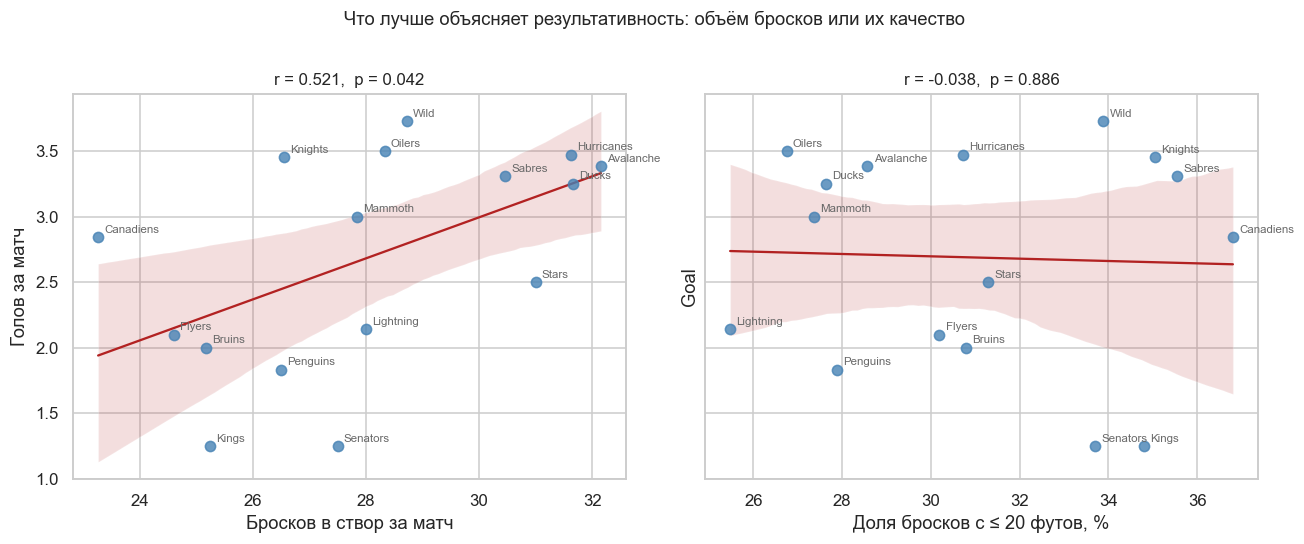

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)

for ax, col, label in zip(
        axes,
        ['Shot', 'Доля с ≤ 20 футов, %'],
        ['Бросков в створ за матч', 'Доля бросков с ≤ 20 футов, %']):
    sns.regplot(data=model, x=col, y='Goal', ax=ax,
                scatter_kws=dict(s=45, color='steelblue', zorder=3),
                line_kws=dict(color='firebrick', lw=1.5))
    for team, row in model.iterrows():
        ax.annotate(team.split()[-1], (row[col], row['Goal']), fontsize=7.5,
                    color='dimgray', xytext=(4, 3), textcoords='offset points')
    r, p = perm_corr(model[col], model['Goal'])
    ax.set_xlabel(label)
    ax.set_title(f'r = {r:.3f},  p = {p:.3f}')

axes[0].set_ylabel('Голов за матч')
fig.suptitle('Что лучше объясняет результативность: объём бросков или их качество', y=1.02)
fig.tight_layout()
fig.savefig(FIGDIR / 'fig11_volume_vs_quality.png')
plt.show()

### Ответ на вопрос

Результат получился **противоположным исходной гипотезе**, и это, пожалуй, самое интересное в
исследовании.

**На уровне отдельного броска расстояние решает почти всё; на уровне команды за один
плей‑офф оно не объясняет ничего, а объём бросков — объясняет.**

Конкретно:

1. **Вероятность гола резко падает с расстоянием** — от ≈ 15 % с пятачка до ≈ 1.6 % с 60–80
   футов, то есть **в 9 раз**. Это самый надёжный результат всего исследования: он получен
   на 7 266 бросках, зависимость монотонна на всём диапазоне до 80 футов, а доверительные
   интервалы дальних и ближних интервалов не пересекаются.

2. **Но на уровне команд качество позиций не работает совсем.** Корреляция средней дистанции
   с результативностью — $r = 0.026$ ($p = 0.93$), доли близких бросков — $r = -0.038$
   ($p = 0.88$). То есть связи нет вообще, причём даже знак у второго показателя «неправильный».

3. **Причина — в шаге 2:** команды по средней дистанции броска статистически неразличимы
   ($p = 0.26$, разброс всего 1.66 фута на уровне 33–39). Показатель, который почти не
   варьируется между командами, по определению не может объяснить различия между ними.
   Оборона в плей‑офф выравнивает всех: с пятачка не бросает никто существенно чаще других.

4. **Объём бросков, наоборот, работает:** $r = 0.521$, $p = 0.042$ — единственный из трёх
   показателей, дающий значимую связь. Варьируется он заметно (от 23 до 32 бросков за матч),
   поэтому и объясняет часть различий.

5. **Чего не хватает в обеих моделях — реализации.** Разброс конверсии по командам огромен:
   от **4.5 %** у «Оттавы» до **13.0 %** у «Вегаса», то есть почти втрое, и дистанцией он не
   объясняется. Именно реализация (исполнительское мастерство, игра вратарей соперника, доля
   бросков в большинстве) и составляет те самые «остальные 73 %» из п. 13.

Проверим пункт 5 напрямую: построим простейшую модель ожидаемых голов (xG) по кривой из
шага 1 — каждому броску приписываем вероятность гола по его дистанции — и посмотрим, насколько
факт расходится с ожиданием.

In [76]:
bin_rate = (conversion['Goals'] / conversion['Shots'])
shots_q['xG'] = shots_q['Distance bin'].map(bin_rate).astype(float)

xg = shots_q.groupby('Team Making the Play').agg(
    **{'xG': ('xG', 'sum'), 'Голов': ('Play Type', lambda s: (s == 'goal').sum())})
xg['xG за матч'] = xg['xG'] / games_played
xg['Голов за матч'] = xg['Голов'] / games_played
xg['Сверх ожидания'] = xg['Голов'] - xg['xG']
xg = xg.sort_values('Сверх ожидания', ascending=False)

r, p = perm_corr(xg['xG за матч'], xg['Голов за матч'])
print(f'корреляция xG и фактических голов за матч: r = {r:.3f}, p = {p:.4f}')
xg.round(2)

корреляция xG и фактических голов за матч: r = 0.347, p = 0.1842


,xG,Голов,xG за матч,Голов за матч,Сверх ожидания
Team Making the Play,,,,,
Vegas Golden Knights,65.280,76,2.970,3.450,10.720
Minnesota Wild,32.010,41,2.910,3.730,8.990
Montréal Canadiens,48.030,54,2.530,2.840,5.970
Edmonton Oilers,16.190,21,2.700,3.500,4.810
Colorado Avalanche,41.230,44,3.170,3.380,2.770
Anaheim Ducks,37.430,39,3.120,3.250,1.570
Carolina Hurricanes,65.100,66,3.430,3.470,0.900
Utah Mammoth,17.590,18,2.930,3.000,0.410
Buffalo Sabres,45.010,43,3.460,3.310,-2.010


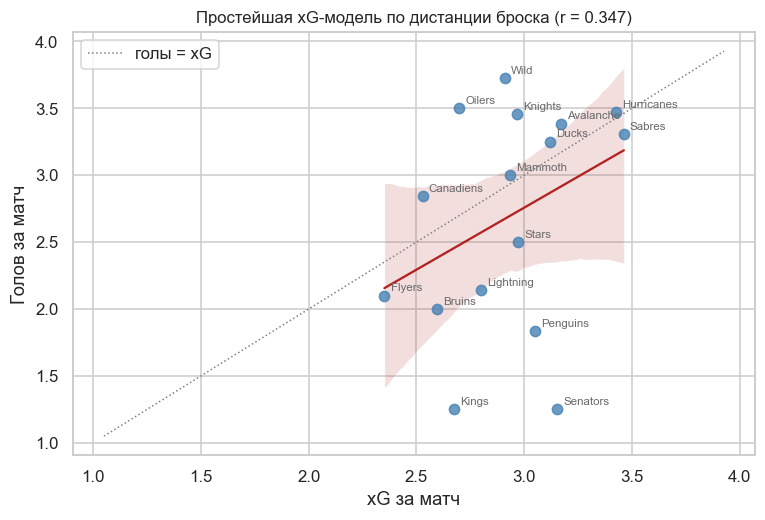

In [77]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=xg, x='xG за матч', y='Голов за матч', ax=ax,
            scatter_kws=dict(s=45, color='steelblue', zorder=3),
            line_kws=dict(color='firebrick', lw=1.5))
lims = [xg[['xG за матч', 'Голов за матч']].min().min() - .2,
        xg[['xG за матч', 'Голов за матч']].max().max() + .2]
ax.plot(lims, lims, ls=':', color='gray', lw=1, label='голы = xG')
for team, row in xg.iterrows():
    ax.annotate(team.split()[-1], (row['xG за матч'], row['Голов за матч']), fontsize=7.5,
                color='dimgray', xytext=(4, 3), textcoords='offset points')
ax.set_title(f'Простейшая xG-модель по дистанции броска (r = {r:.3f})')
ax.legend()
fig.savefig(FIGDIR / 'fig12_xg.png')
plt.show()

Числа подтверждают пункт 5 и закрывают вопрос. Одномерная xG‑модель даёт $r = 0.347$
($p = 0.18$) — то есть **хуже**, чем простой подсчёт бросков ($r = 0.521$), и уже незначимо.
Причина та же: взвешивая броски по дистанции, модель почти не меняет их суммы (команды по
дистанции неразличимы), зато теряет часть информации об объёме.

Зато колонка «Сверх ожидания» показывает, где спрятаны недостающие три четверти дисперсии:
**«Вегас» забил на 10.7 гола больше ожидаемого, «Оттава» — на 7.6 меньше**, при почти
одинаковом xG за матч (2.97 против 3.15). Разброс по этой колонке — 18 голов от края до края,
что сопоставимо с общим числом голов у слабых команд. Команды выше пунктирной линии
(Вегас, Миннесота, Монреаль, Эдмонтон) реализовывали шансы лучше ожидаемого, ниже
(Оттава, Питтсбург, Лос‑Анджелес) — хуже.

**Содержательный итог.** Геометрия броска определяет его опасность очень сильно, но в плей‑офф
все команды поставлены в одинаковые геометрические условия. Различает их не то, *откуда* они
бросают, а *сколько* и, главным образом, *как* реализуют. Для содержательной оценки команд
одномерной xG недостаточно — нужны признаки сверх дистанции (угол, тип броска, численное
преимущество, предшествующее событие) либо данные за несколько сезонов.

---

# Итоги

**По формальной части.** Все 22 пункта выполнены; результаты, для которых в условии приведены
примеры (пп. 1–4, 6, 8, 10–12, 14), совпадают с ними **в точности** — включая значения с
точностью до третьего знака в пп. 8, 10–12. Единственное расхождение — п. 7 (40 игроков против
41 в условии), и оно разобрано: в условии посчитана пустая ячейка.

**По содержательной части.**

1. **Результативность.** 5.93 гола за матч, распределение близко к пуассоновскому с обрезанным
   нулём и одним выбросом на 15 голах.
2. **Броски.** Около двух третей незаблокированных бросков достигают створа. Перестановочные
   тесты показали, что команды статистически неразличимы **ни** по доле точных бросков
   ($p = 0.21$), **ни** по средней дистанции броска ($p = 0.26$): и то, и другое —
   характеристики лиги, а не отличительные черты команд.
3. **Длинный хвост точных бросков** объясняется не мастерством, а асимметрией протокола:
   дальний бросок, дошедший до вратаря, регистрируется, а такой же промах — обычно нет
   (4.78 % длинных среди точных против 1.14 % среди неточных).
4. **Объём против качества.** Связь «броски → голы» положительна и значима
   ($r = 0.52$, $p = 0.04$, $R^2 = 0.27$), устойчива к удалению любой одной команды.
   А вот качество позиций на уровне команд не работает вовсе ($r = 0.03$ для средней дистанции,
   $r = -0.04$ для доли близких бросков), и простейшая xG‑модель по одной дистанции
   ($r = 0.35$) оказывается хуже обычного подсчёта бросков. Исходная гипотеза
   «качество важнее количества» **опровергнута** — потому что варьироваться качеству
   позиций оборона соперника просто не даёт.
5. **Главный количественный результат** — кривая опасности: вероятность гола падает с ≈ 15 %
   с пятачка до ≈ 1.6 % с 60–80 футов, то есть в 9 раз. Остальные различия между командами
   объясняются реализацией: от 4.5 % у «Оттавы» до 13.0 % у «Вегаса».

**Замеченные особенности данных** (все проверены и задокументированы по ходу работы):

* у всех 22 победных голов в овертайме отсутствует информация о составах на льду — системный
  пропуск, из‑за которого п. 21 требует отдельной поправки;
* в каждом матче среди полей «игроки на льду» есть ровно одна пустая ячейка (п. 7);
* 3 гола забиты в пустые ворота и корректно не отнесены ни к одному вратарю;
* поле `Play Zone` полностью согласовано с геометрией координат (6 884 из 6 896 совпадений
  в зоне атаки), что подтверждает правильность определения направления атаки в п. 8;
* сторона защиты хозяев в первом периоде не постоянна по выборке (51 матч `right`,
  31 — `left`), поэтому в п. 15 нормировка координат сделана по полю
  `Home Team's Defending Side`, а не по чётности периода.